# Dimensions³ — Jebel Ali Flood Evidence Pipeline

## Project objective

This notebook combines multiple Earth Observation and supporting data sources to identify
preliminary flood-related surface changes around Jebel Ali, Dubai, during the April 2024
extreme rainfall event.

## Study area

Jebel Ali, Dubai, United Arab Emirates

Approximate bounding box:

- West: 55.00
- South: 24.90
- East: 55.10
- North: 25.00

## Study period

1 April 2024 to 30 April 2024

Main rainfall-event window:

15 April 2024 to 17 April 2024

## Data sources

1. Sentinel-1 radar imagery  
   Used to detect surface changes before and after the event.

2. Sentinel-2 optical imagery  
   Used to calculate water-related spectral indices such as MNDWI.

3. Landsat 9 imagery  
   Used as an independent before/after visual reference.

4. Weather data  
   Used to identify rainfall intensity and event timing.

5. Official news and government reports  
   Used to validate the timing and regional impact of the event.

## Planned workflow

Data collection → preprocessing → individual satellite analysis →
cross-source comparison → preliminary flood detection → final evidence dashboard

## Important limitation

The final result will be presented as preliminary flood screening.
Exact flooded boundaries require georeferenced, terrain-corrected Sentinel-1 data
and local validation.

In [18]:
# ============================================================
# PROJECT SETUP AND DATA PACKETS
# ============================================================

# Install the main Earth Observation and analysis libraries.
# Run this cell once at the beginning of the notebook.

!pip -q install pystac-client planetary-computer stackstac \
    rasterio rioxarray geopandas shapely requests \
    pandas numpy matplotlib scikit-image

import os
import json
from datetime import datetime

# ------------------------------------------------------------
# 1. Project information
# ------------------------------------------------------------

PROJECT_NAME = "Dimensions3"
PROJECT_TITLE = "Jebel Ali Flood Evidence Analysis"
AOI_NAME = "Jebel Ali, Dubai, UAE"

# Approximate bounding box:
# [west, south, east, north]
BBOX = [
    55.00,   # west
    24.90,   # south
    55.10,   # east
    25.00    # north
]

STUDY_START = "2024-04-01"
STUDY_END = "2024-04-30"

EVENT_START = "2024-04-15"
EVENT_END = "2024-04-17"

# ------------------------------------------------------------
# 2. Create project folders
# ------------------------------------------------------------

BASE_DIR = "/content/dimensions3_project"

DATA_DIR = os.path.join(
    BASE_DIR,
    "data"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "outputs"
)

PACKETS_DIR = os.path.join(
    BASE_DIR,
    "packets"
)

SENTINEL1_DIR = os.path.join(
    PACKETS_DIR,
    "sentinel1"
)

SENTINEL2_DIR = os.path.join(
    PACKETS_DIR,
    "sentinel2"
)

LANDSAT9_DIR = os.path.join(
    PACKETS_DIR,
    "landsat9"
)

WEATHER_DIR = os.path.join(
    PACKETS_DIR,
    "weather"
)

REPORTS_DIR = os.path.join(
    PACKETS_DIR,
    "reports"
)

for folder in [
    BASE_DIR,
    DATA_DIR,
    OUTPUT_DIR,
    PACKETS_DIR,
    SENTINEL1_DIR,
    SENTINEL2_DIR,
    LANDSAT9_DIR,
    WEATHER_DIR,
    REPORTS_DIR
]:
    os.makedirs(folder, exist_ok=True)

# ------------------------------------------------------------
# 3. Create project manifest
# ------------------------------------------------------------

project_manifest = {
    "project_name": PROJECT_NAME,
    "project_title": PROJECT_TITLE,
    "study_area": AOI_NAME,
    "bbox": BBOX,
    "study_period": {
        "start": STUDY_START,
        "end": STUDY_END
    },
    "event_window": {
        "start": EVENT_START,
        "end": EVENT_END
    },
    "data_packets": {
        "sentinel1": {
            "purpose": "Radar-based surface-change detection",
            "status": "planned"
        },
        "sentinel2": {
            "purpose": "Optical water and land-surface analysis",
            "status": "planned"
        },
        "landsat9": {
            "purpose": "Independent before/after visual validation",
            "status": "planned"
        },
        "weather": {
            "purpose": "Rainfall and environmental-event context",
            "status": "planned"
        },
        "reports": {
            "purpose": "Official and public event validation",
            "status": "planned"
        }
    },
    "future_analysis": {
        "baseline": [
            "MNDWI water detection",
            "Sentinel-1 radar change",
            "rainfall alignment",
            "evidence fusion"
        ],
        "future_models": [
            "Random Forest",
            "XGBoost",
            "CNN",
            "U-Net flood segmentation"
        ]
    },
    "created_at": datetime.utcnow().isoformat()
}

manifest_path = os.path.join(
    BASE_DIR,
    "project_manifest.json"
)

with open(manifest_path, "w") as file:
    json.dump(
        project_manifest,
        file,
        indent=2
    )

# ------------------------------------------------------------
# 4. Print setup summary
# ------------------------------------------------------------

print("============================================================")
print("DIMENSIONS3 PROJECT INITIALIZED")
print("============================================================")
print("Project:", PROJECT_TITLE)
print("Study area:", AOI_NAME)
print("Study period:", STUDY_START, "to", STUDY_END)
print("Main event window:", EVENT_START, "to", EVENT_END)
print()
print("Data packets created:")
print("- Sentinel-1:", SENTINEL1_DIR)
print("- Sentinel-2:", SENTINEL2_DIR)
print("- Landsat 9:", LANDSAT9_DIR)
print("- Weather:", WEATHER_DIR)
print("- Reports:", REPORTS_DIR)
print()
print("Outputs folder:", OUTPUT_DIR)
print("Manifest saved:", manifest_path)
print()
print("CELL 2 COMPLETE")

DIMENSIONS3 PROJECT INITIALIZED
Project: Jebel Ali Flood Evidence Analysis
Study area: Jebel Ali, Dubai, UAE
Study period: 2024-04-01 to 2024-04-30
Main event window: 2024-04-15 to 2024-04-17

Data packets created:
- Sentinel-1: /content/dimensions3_project/packets/sentinel1
- Sentinel-2: /content/dimensions3_project/packets/sentinel2
- Landsat 9: /content/dimensions3_project/packets/landsat9
- Weather: /content/dimensions3_project/packets/weather
- Reports: /content/dimensions3_project/packets/reports

Outputs folder: /content/dimensions3_project/outputs
Manifest saved: /content/dimensions3_project/project_manifest.json

CELL 2 COMPLETE


/tmp/ipykernel_21886/845239622.py:149: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "created_at": datetime.utcnow().isoformat()


In [19]:
# ============================================================
# CELL 3 — SENTINEL-2 DATA PACKET
# RATE-LIMIT-SAFE VERSION
# ============================================================

import os
import json
import time
import pandas as pd
import planetary_computer
import stackstac

from pystac_client import Client
from pystac_client.exceptions import APIError

print("============================================================")
print("SENTINEL-2 DATA COLLECTION")
print("============================================================")

# ------------------------------------------------------------
# 1. Connect to the catalogue
# ------------------------------------------------------------

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)

# ------------------------------------------------------------
# 2. Search with a narrow request
# ------------------------------------------------------------

search_parameters = {
    "collections": ["sentinel-2-l2a"],
    "bbox": BBOX,
    "datetime": "2024-04-01/2024-04-30",
    "limit": 50,
    "max_items": 50,
    "query": {
        "eo:cloud_cover": {
            "lt": 40
        },
        "s2:mgrs_tile": {
            "eq": "40RBN"
        }
    }
}

sentinel2_items = None

for attempt in range(3):

    try:
        print(
            f"Connecting to catalogue "
            f"(attempt {attempt + 1}/3)..."
        )

        search = catalog.search(
            **search_parameters
        )

        sentinel2_items = list(
            search.item_collection()
        )

        break

    except APIError as error:

        print("Catalogue request was rate-limited.")
        print("Waiting before retrying...")

        if attempt < 2:
            time.sleep(45)
        else:
            raise error

if not sentinel2_items:
    raise ValueError(
        "No Sentinel-2 scenes were returned."
    )

print(
    "\nSentinel-2 scenes found:",
    len(sentinel2_items)
)

# ------------------------------------------------------------
# 3. Create a scene table
# ------------------------------------------------------------

sentinel2_rows = []

for item in sentinel2_items:

    sentinel2_rows.append({
        "scene_id": item.id,
        "date": str(item.datetime.date()),
        "tile": item.properties.get(
            "s2:mgrs_tile"
        ),
        "cloud_percent": item.properties.get(
            "eo:cloud_cover"
        ),
        "platform": item.properties.get(
            "platform"
        )
    })

sentinel2_table = pd.DataFrame(
    sentinel2_rows
)

sentinel2_table = sentinel2_table.sort_values(
    by=["date", "cloud_percent"]
).reset_index(drop=True)

print("\nAvailable scenes:")
display(sentinel2_table)

# ------------------------------------------------------------
# 4. Select before and after scenes
# ------------------------------------------------------------

def select_scene(date_text):

    candidates = [
        item for item in sentinel2_items
        if str(item.datetime.date()) == date_text
    ]

    if not candidates:
        raise ValueError(
            f"No Sentinel-2 scene found for {date_text}"
        )

    return min(
        candidates,
        key=lambda item: item.properties.get(
            "eo:cloud_cover",
            100
        )
    )

sentinel2_before = select_scene(
    "2024-04-12"
)

sentinel2_after = select_scene(
    "2024-04-22"
)

print("\nSelected scenes:")

print("\nBEFORE")
print("ID:", sentinel2_before.id)
print("Date:", sentinel2_before.datetime)
print(
    "Cloud cover:",
    sentinel2_before.properties.get(
        "eo:cloud_cover"
    ),
    "%"
)

print("\nAFTER")
print("ID:", sentinel2_after.id)
print("Date:", sentinel2_after.datetime)
print(
    "Cloud cover:",
    sentinel2_after.properties.get(
        "eo:cloud_cover"
    ),
    "%"
)

# ------------------------------------------------------------
# 5. Save metadata packet
# ------------------------------------------------------------

sentinel2_metadata = {
    "packet": "sentinel2",
    "purpose": (
        "Multispectral water and land-surface analysis"
    ),
    "before_scene": sentinel2_before.id,
    "after_scene": sentinel2_after.id,
    "before_date": str(
        sentinel2_before.datetime
    ),
    "after_date": str(
        sentinel2_after.datetime
    ),
    "before_cloud_cover": sentinel2_before.properties.get(
        "eo:cloud_cover"
    ),
    "after_cloud_cover": sentinel2_after.properties.get(
        "eo:cloud_cover"
    ),
    "tile": "40RBN",
    "bands": [
        "B02",
        "B03",
        "B04",
        "B08",
        "B11",
        "SCL"
    ],
    "resolution_m": 20,
    "aoi": AOI_NAME
}

sentinel2_metadata_path = os.path.join(
    SENTINEL2_DIR,
    "sentinel2_metadata.json"
)

with open(
    sentinel2_metadata_path,
    "w"
) as file:
    json.dump(
        sentinel2_metadata,
        file,
        indent=2
    )

# ------------------------------------------------------------
# 6. Sign catalogue items
# ------------------------------------------------------------

before_signed = planetary_computer.sign(
    sentinel2_before
)

after_signed = planetary_computer.sign(
    sentinel2_after
)

# ------------------------------------------------------------
# 7. Load selected Sentinel-2 bands
# ------------------------------------------------------------

selected_bands = [
    "B02",
    "B03",
    "B04",
    "B08",
    "B11",
    "SCL"
]

print("\nDownloading Sentinel-2 bands:")
print(selected_bands)
print("Resolution: 20 metres")

sentinel2_stack = stackstac.stack(
    [
        before_signed,
        after_signed
    ],
    assets=selected_bands,
    resolution=20,
    bounds_latlon=BBOX,
    epsg=32640,
    chunksize=1024
).compute()

print("\nSentinel-2 download complete.")
print("Dimensions:", sentinel2_stack.dims)
print("Shape:", sentinel2_stack.shape)

# ------------------------------------------------------------
# 8. Save summary
# ------------------------------------------------------------

sentinel2_summary = {
    "packet": "sentinel2",
    "scenes": 2,
    "bands": selected_bands,
    "shape": [
        int(value)
        for value in sentinel2_stack.shape
    ],
    "status": "downloaded_and_loaded"
}

sentinel2_summary_path = os.path.join(
    SENTINEL2_DIR,
    "sentinel2_summary.json"
)

with open(
    sentinel2_summary_path,
    "w"
) as file:
    json.dump(
        sentinel2_summary,
        file,
        indent=2
    )

print("\nMetadata saved:", sentinel2_metadata_path)
print("Summary saved:", sentinel2_summary_path)
print("\nCELL 3 COMPLETE")

SENTINEL-2 DATA COLLECTION
Connecting to catalogue (attempt 1/3)...

Sentinel-2 scenes found: 5

Available scenes:


,scene_id,date,tile,cloud_percent,platform
0,S2A_MSIL2A_20240407T064621_R020_T40RBN_2024040...,2024-04-07,40RBN,39.455390,Sentinel-2A
1,S2B_MSIL2A_20240412T064629_R020_T40RBN_2024041...,2024-04-12,40RBN,26.731876,Sentinel-2B
2,S2A_MSIL2A_20240417T064631_R020_T40RBN_2024041...,2024-04-17,40RBN,33.302638,Sentinel-2A
3,S2B_MSIL2A_20240422T064629_R020_T40RBN_2024042...,2024-04-22,40RBN,8.976509,Sentinel-2B
4,S2A_MSIL2A_20240427T064631_R020_T40RBN_2024042...,2024-04-27,40RBN,6.643882,Sentinel-2A



Selected scenes:

BEFORE
ID: S2B_MSIL2A_20240412T064629_R020_T40RBN_20240412T112725
Date: 2024-04-12 06:46:29.024000+00:00
Cloud cover: 26.731876 %

AFTER
ID: S2B_MSIL2A_20240422T064629_R020_T40RBN_20240422T102818
Date: 2024-04-22 06:46:29.024000+00:00
Cloud cover: 8.976509 %

['B02', 'B03', 'B04', 'B08', 'B11', 'SCL']
Resolution: 20 metres



Sentinel-2 download complete.
Dimensions: ('time', 'band', 'y', 'x')
Shape: (2, 6, 562, 514)

Metadata saved: /content/dimensions3_project/packets/sentinel2/sentinel2_metadata.json
Summary saved: /content/dimensions3_project/packets/sentinel2/sentinel2_summary.json

CELL 3 COMPLETE


SENTINEL-2 IMAGE VISUALIZATION


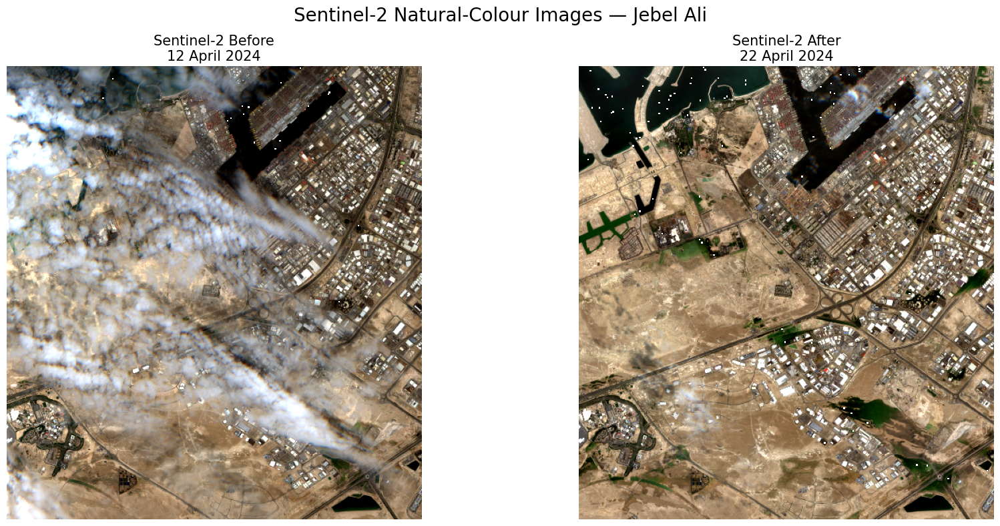

Sentinel-2 RGB figure saved:
/content/dimensions3_project/outputs/sentinel2_before_after_rgb.png

Image interpretation:
- The before image is the pre-event reference.
- The after image is the post-event comparison.
- Existing sea and permanent water must not be counted as new flooding.
- Cloud and haze can reduce the reliability of optical interpretation.

CELL 4 COMPLETE


In [20]:
# ============================================================
# CELL 4 — SENTINEL-2 VISUALIZATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

print("============================================================")
print("SENTINEL-2 IMAGE VISUALIZATION")
print("============================================================")

# ------------------------------------------------------------
# 1. Extract one band from the Sentinel-2 stack
# ------------------------------------------------------------

def get_sentinel2_band(
    scene_index,
    band_name
):
    return sentinel2_stack.sel(
        time=sentinel2_stack.time.values[scene_index],
        band=band_name
    ).values.astype("float32")

# ------------------------------------------------------------
# 2. Create natural-colour RGB images
#
# Red   = B04
# Green = B03
# Blue  = B02
# ------------------------------------------------------------

def create_rgb_image(scene_index):

    red = get_sentinel2_band(
        scene_index,
        "B04"
    )

    green = get_sentinel2_band(
        scene_index,
        "B03"
    )

    blue = get_sentinel2_band(
        scene_index,
        "B02"
    )

    rgb = np.stack(
        [red, green, blue],
        axis=-1
    )

    # Improve visual contrast using percentiles
    valid_values = rgb[
        np.isfinite(rgb)
    ]

    low, high = np.percentile(
        valid_values,
        [2, 98]
    )

    rgb = np.clip(
        (rgb - low) / (high - low),
        0,
        1
    )

    return rgb

before_rgb = create_rgb_image(0)
after_rgb = create_rgb_image(1)

# ------------------------------------------------------------
# 3. Display before and after images
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 8)
)

axes[0].imshow(before_rgb)
axes[0].set_title(
    "Sentinel-2 Before\n12 April 2024",
    fontsize=15
)
axes[0].axis("off")

axes[1].imshow(after_rgb)
axes[1].set_title(
    "Sentinel-2 After\n22 April 2024",
    fontsize=15
)
axes[1].axis("off")

plt.suptitle(
    "Sentinel-2 Natural-Colour Images — Jebel Ali",
    fontsize=20
)

plt.tight_layout()

sentinel2_rgb_path = os.path.join(
    OUTPUT_DIR,
    "sentinel2_before_after_rgb.png"
)

plt.savefig(
    sentinel2_rgb_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Sentinel-2 RGB figure saved:")
print(sentinel2_rgb_path)
print()
print("Image interpretation:")
print("- The before image is the pre-event reference.")
print("- The after image is the post-event comparison.")
print("- Existing sea and permanent water must not be counted as new flooding.")
print("- Cloud and haze can reduce the reliability of optical interpretation.")
print()
print("CELL 4 COMPLETE")

SENTINEL-1 COMPLETE DATA PACKET
Before product root:
/content/dimensions3_project/packets/sentinel1/raw_products/2024-04-12_before/2024-04-12_before

After product root:
/content/dimensions3_project/packets/sentinel1/raw_products/2024-04-24_after/2024-04-24_after

12 APRIL 2024 — BEFORE
--------------------------------------------------
Manifest files: 1
Measurement TIFFs: 2
Annotation XMLs: 8
Calibration XMLs: 4
Noise XMLs: 2
RFI XMLs: 2
KML files: 1
Measurement: s1a-iw-grd-vh-20240412t142512-20240412t142537-053402-067a39-002.tiff
Measurement: s1a-iw-grd-vv-20240412t142512-20240412t142537-053402-067a39-001.tiff

24 APRIL 2024 — AFTER
--------------------------------------------------
Manifest files: 1
Measurement TIFFs: 2
Annotation XMLs: 8
Calibration XMLs: 4
Noise XMLs: 2
RFI XMLs: 2
KML files: 1
Measurement: s1a-iw-grd-vh-20240424t142514-20240424t142539-053577-068115-002.tiff
Measurement: s1a-iw-grd-vv-20240424t142514-20240424t142539-053577-068115-001.tiff

Selected measurement fil

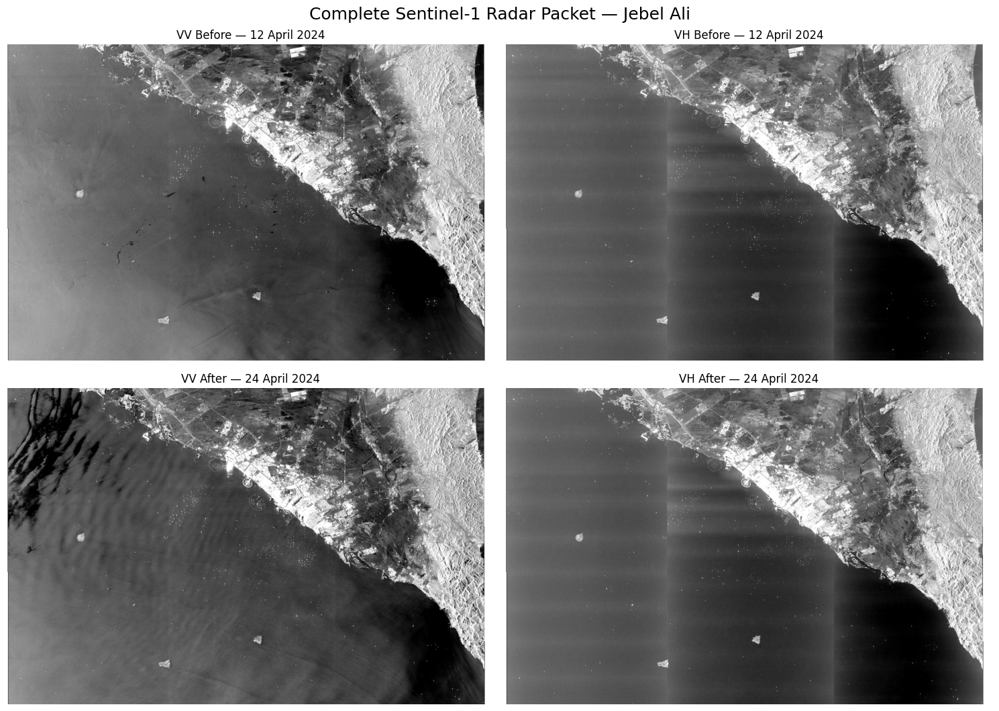


Radar figure saved:
/content/dimensions3_project/outputs/sentinel1_complete_before_after.png

Metadata saved:
/content/dimensions3_project/packets/sentinel1/sentinel1_complete_metadata.json

CELL 5 COMPLETE


In [21]:
# ============================================================
# CELL 5 — COMPLETE SENTINEL-1 DATA PACKET
# CORRECTED NESTED-FOLDER VERSION
# ============================================================

import os
import glob
import json
import numpy as np
import matplotlib.pyplot as plt
import rasterio

from rasterio.enums import Resampling

print("============================================================")
print("SENTINEL-1 COMPLETE DATA PACKET")
print("============================================================")

# ------------------------------------------------------------
# 1. Locate the actual product roots
# ------------------------------------------------------------

before_parent = os.path.join(
    SENTINEL1_DIR,
    "raw_products",
    "2024-04-12_before"
)

after_parent = os.path.join(
    SENTINEL1_DIR,
    "raw_products",
    "2024-04-24_after"
)

def find_manifest_root(parent_folder):
    manifests = glob.glob(
        os.path.join(
            parent_folder,
            "**",
            "manifest.safe"
        ),
        recursive=True
    )

    if not manifests:
        raise FileNotFoundError(
            f"manifest.safe not found inside {parent_folder}"
        )

    return os.path.dirname(manifests[0])

before_root = find_manifest_root(
    before_parent
)

after_root = find_manifest_root(
    after_parent
)

print("Before product root:")
print(before_root)

print("\nAfter product root:")
print(after_root)

# ------------------------------------------------------------
# 2. Find all product components
# ------------------------------------------------------------

def inspect_product(
    product_root,
    label
):
    all_files = glob.glob(
        os.path.join(
            product_root,
            "**",
            "*"
        ),
        recursive=True
    )

    all_files = [
        path for path in all_files
        if os.path.isfile(path)
    ]

    measurement_files = [
        path for path in all_files
        if path.lower().endswith(
            (".tif", ".tiff")
        )
    ]

    annotation_files = [
        path for path in all_files
        if "annotation" in path.lower()
        and path.lower().endswith(".xml")
    ]

    calibration_files = [
        path for path in all_files
        if "calibration" in path.lower()
        and path.lower().endswith(".xml")
    ]

    noise_files = [
        path for path in all_files
        if "noise-" in os.path.basename(
            path
        ).lower()
    ]

    rfi_files = [
        path for path in all_files
        if "rfi" in path.lower()
        and path.lower().endswith(".xml")
    ]

    kml_files = [
        path for path in all_files
        if path.lower().endswith(".kml")
    ]

    manifest_files = [
        path for path in all_files
        if os.path.basename(
            path
        ).lower() == "manifest.safe"
    ]

    print("\n" + label)
    print("-" * 50)
    print("Manifest files:", len(manifest_files))
    print("Measurement TIFFs:", len(measurement_files))
    print("Annotation XMLs:", len(annotation_files))
    print("Calibration XMLs:", len(calibration_files))
    print("Noise XMLs:", len(noise_files))
    print("RFI XMLs:", len(rfi_files))
    print("KML files:", len(kml_files))

    for path in measurement_files:
        print(
            "Measurement:",
            os.path.basename(path)
        )

    return {
        "all_files": all_files,
        "measurement_files": measurement_files,
        "annotation_files": annotation_files,
        "calibration_files": calibration_files,
        "noise_files": noise_files,
        "rfi_files": rfi_files,
        "kml_files": kml_files,
        "manifest_files": manifest_files
    }

before_info = inspect_product(
    before_root,
    "12 APRIL 2024 — BEFORE"
)

after_info = inspect_product(
    after_root,
    "24 APRIL 2024 — AFTER"
)

# ------------------------------------------------------------
# 3. Select VV and VH measurement TIFFs
# ------------------------------------------------------------

def select_polarization_file(
    measurement_files,
    polarization
):
    matches = [
        path for path in measurement_files
        if f"-{polarization.lower()}-"
        in os.path.basename(path).lower()
    ]

    if not matches:
        raise FileNotFoundError(
            f"No {polarization.upper()} measurement TIFF found."
        )

    return matches[0]

s1_before_vv_path = select_polarization_file(
    before_info["measurement_files"],
    "vv"
)

s1_before_vh_path = select_polarization_file(
    before_info["measurement_files"],
    "vh"
)

s1_after_vv_path = select_polarization_file(
    after_info["measurement_files"],
    "vv"
)

s1_after_vh_path = select_polarization_file(
    after_info["measurement_files"],
    "vh"
)

print("\nSelected measurement files:")
print("Before VV:", os.path.basename(s1_before_vv_path))
print("Before VH:", os.path.basename(s1_before_vh_path))
print("After VV :", os.path.basename(s1_after_vv_path))
print("After VH :", os.path.basename(s1_after_vh_path))

# ------------------------------------------------------------
# 4. Read reduced radar previews
# ------------------------------------------------------------

def read_radar_preview(
    file_path,
    max_dimension=1500
):
    with rasterio.open(file_path) as source:

        scale = min(
            1.0,
            max_dimension
            / max(source.height, source.width)
        )

        height = max(
            1,
            int(source.height * scale)
        )

        width = max(
            1,
            int(source.width * scale)
        )

        image = source.read(
            1,
            out_shape=(height, width),
            resampling=Resampling.average
        ).astype("float32")

        image = np.ma.filled(
            image,
            np.nan
        )

        image[image <= 0] = np.nan

        image_db = 10 * np.log10(image)

        metadata = {
            "original_height": source.height,
            "original_width": source.width,
            "preview_height": height,
            "preview_width": width,
            "crs": str(source.crs),
            "dtype": str(source.dtypes[0])
        }

    return image_db, metadata

print("\nReading radar previews...")

s1_before_vv_db, s1_before_metadata = (
    read_radar_preview(
        s1_before_vv_path
    )
)

s1_before_vh_db, _ = (
    read_radar_preview(
        s1_before_vh_path
    )
)

s1_after_vv_db, s1_after_metadata = (
    read_radar_preview(
        s1_after_vv_path
    )
)

s1_after_vh_db, _ = (
    read_radar_preview(
        s1_after_vh_path
    )
)

print(
    "Radar preview shape:",
    s1_before_vv_db.shape
)

# ------------------------------------------------------------
# 5. Display all radar images
# ------------------------------------------------------------

def contrast_limits(image):
    valid = image[
        np.isfinite(image)
    ]

    return np.percentile(
        valid,
        [2, 98]
    )

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 11)
)

radar_images = [
    (
        s1_before_vv_db,
        "VV Before — 12 April 2024"
    ),
    (
        s1_before_vh_db,
        "VH Before — 12 April 2024"
    ),
    (
        s1_after_vv_db,
        "VV After — 24 April 2024"
    ),
    (
        s1_after_vh_db,
        "VH After — 24 April 2024"
    )
]

for axis, (
    image,
    title
) in zip(
    axes.ravel(),
    radar_images
):

    low, high = contrast_limits(image)

    axis.imshow(
        image,
        cmap="gray",
        vmin=low,
        vmax=high
    )

    axis.set_title(title)
    axis.axis("off")

plt.suptitle(
    "Complete Sentinel-1 Radar Packet — Jebel Ali",
    fontsize=18
)

plt.tight_layout()

sentinel1_figure_path = os.path.join(
    OUTPUT_DIR,
    "sentinel1_complete_before_after.png"
)

plt.savefig(
    sentinel1_figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 6. Save packet metadata
# ------------------------------------------------------------

sentinel1_complete_metadata = {
    "packet": "sentinel1",
    "before_date": "2024-04-12",
    "after_date": "2024-04-24",
    "before_product_root": before_root,
    "after_product_root": after_root,
    "before_vv": os.path.basename(
        s1_before_vv_path
    ),
    "before_vh": os.path.basename(
        s1_before_vh_path
    ),
    "after_vv": os.path.basename(
        s1_after_vv_path
    ),
    "after_vh": os.path.basename(
        s1_after_vh_path
    ),
    "before_metadata": s1_before_metadata,
    "after_metadata": s1_after_metadata,
    "status": "complete_product_loaded",
    "next_step": (
        "radiometric calibration and terrain correction"
    )
}

sentinel1_metadata_path = os.path.join(
    SENTINEL1_DIR,
    "sentinel1_complete_metadata.json"
)

with open(
    sentinel1_metadata_path,
    "w"
) as file:
    json.dump(
        sentinel1_complete_metadata,
        file,
        indent=2
    )

print("\nRadar figure saved:")
print(sentinel1_figure_path)

print("\nMetadata saved:")
print(sentinel1_metadata_path)

print("\n============================================================")
print("CELL 5 COMPLETE")
print("============================================================")

In [22]:
# ============================================================
# CELL 6 — LANDSAT 9 DATA PACKET
# DIRECT CLOUD-OPTIMIZED GEOTIFF VERSION
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import planetary_computer

from pystac_client import Client
from pystac_client.exceptions import APIError
from rasterio.windows import from_bounds
from rasterio.enums import Resampling
from rasterio.warp import transform_bounds

print("============================================================")
print("LANDSAT 9 DATA COLLECTION")
print("============================================================")

# ------------------------------------------------------------
# 1. Search Landsat 9 scenes
# ------------------------------------------------------------

landsat_catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)

landsat_items = None

for attempt in range(3):

    try:

        print(
            f"Searching catalogue "
            f"(attempt {attempt + 1}/3)..."
        )

        search = landsat_catalog.search(
            collections=["landsat-c2-l2"],
            bbox=BBOX,
            datetime="2024-04-01/2024-04-30",
            limit=50,
            max_items=50,
            query={
                "eo:cloud_cover": {
                    "lt": 60
                }
            }
        )

        landsat_items = list(
            search.item_collection()
        )

        break

    except APIError as error:

        print("Catalogue rate limit encountered.")

        if attempt < 2:
            time.sleep(45)
        else:
            raise error

# Keep Landsat 9 only
landsat9_items = [
    item for item in landsat_items
    if item.properties.get(
        "platform"
    ) == "landsat-9"
]

print(
    "\nLandsat 9 scenes found:",
    len(landsat9_items)
)

# ------------------------------------------------------------
# 2. Create scene table
# ------------------------------------------------------------

landsat_rows = []

for item in landsat9_items:

    landsat_rows.append({
        "scene_id": item.id,
        "date": str(item.datetime.date()),
        "cloud_percent": item.properties.get(
            "eo:cloud_cover"
        ),
        "platform": item.properties.get(
            "platform"
        )
    })

landsat_table = pd.DataFrame(
    landsat_rows
)

landsat_table = landsat_table.sort_values(
    by=["date", "cloud_percent"]
).reset_index(drop=True)

display(landsat_table)

# ------------------------------------------------------------
# 3. Select before and after scenes
# ------------------------------------------------------------

def select_landsat_scene(
    date_text
):
    matches = [
        item for item in landsat9_items
        if str(item.datetime.date()) == date_text
    ]

    if not matches:
        raise ValueError(
            f"No Landsat 9 scene found for {date_text}"
        )

    return min(
        matches,
        key=lambda item: item.properties.get(
            "eo:cloud_cover",
            100
        )
    )

landsat_before = select_landsat_scene(
    "2024-04-03"
)

landsat_after = select_landsat_scene(
    "2024-04-19"
)

print("\nSelected scenes:")

print("\nBEFORE")
print("ID:", landsat_before.id)
print("Date:", landsat_before.datetime)
print(
    "Cloud cover:",
    landsat_before.properties.get(
        "eo:cloud_cover"
    ),
    "%"
)

print("\nAFTER")
print("ID:", landsat_after.id)
print("Date:", landsat_after.datetime)
print(
    "Cloud cover:",
    landsat_after.properties.get(
        "eo:cloud_cover"
    ),
    "%"
)

# ------------------------------------------------------------
# 4. Sign scenes for secure asset access
# ------------------------------------------------------------

landsat_before_signed = planetary_computer.sign(
    landsat_before
)

landsat_after_signed = planetary_computer.sign(
    landsat_after
)

# ============================================================
# CELL 6B — LOAD LANDSAT 9 BANDS
# CORRECT PLANETARY COMPUTER ASSET NAMES
# ============================================================

import os
import json
import numpy as np
import rasterio
import planetary_computer

from rasterio.windows import from_bounds
from rasterio.enums import Resampling
from rasterio.warp import transform_bounds

print("============================================================")
print("LOADING LANDSAT 9 REFLECTANCE DATA")
print("============================================================")

# Sign the already-selected scenes
landsat_before_signed = planetary_computer.sign(
    landsat_before
)

landsat_after_signed = planetary_computer.sign(
    landsat_after
)

# Correct Planetary Computer asset names
landsat_band_mapping = {
    "green": "green",
    "nir": "nir08",
    "swir1": "swir16"
}

print("Using Landsat assets:")
print(landsat_band_mapping)

# Print available assets for confirmation
print("\nAvailable assets:")
print(list(landsat_before_signed.assets.keys()))

# ------------------------------------------------------------
# Read only the Jebel Ali AOI from each Landsat asset
# ------------------------------------------------------------

def read_landsat_aoi(
    signed_item,
    max_dimension=1500
):
    arrays = []
    metadata = {}

    for logical_name, asset_name in (
        landsat_band_mapping.items()
    ):

        if asset_name not in signed_item.assets:
            raise KeyError(
                f"Asset '{asset_name}' was not found. "
                f"Available assets: "
                f"{list(signed_item.assets.keys())}"
            )

        asset_href = signed_item.assets[
            asset_name
        ].href

        with rasterio.open(
            asset_href
        ) as source:

            # Transform Jebel Ali BBOX into the source CRS
            source_bounds = transform_bounds(
                "EPSG:4326",
                source.crs,
                BBOX[0],
                BBOX[1],
                BBOX[2],
                BBOX[3]
            )

            window = from_bounds(
                *source_bounds,
                transform=source.transform
            )

            # Keep window inside the image
            window = window.intersection(
                rasterio.windows.Window(
                    0,
                    0,
                    source.width,
                    source.height
                )
            )

            output_height = min(
                max_dimension,
                int(window.height)
            )

            output_width = min(
                max_dimension,
                int(window.width)
            )

            data = source.read(
                1,
                window=window,
                out_shape=(
                    output_height,
                    output_width
                ),
                resampling=Resampling.bilinear
            ).astype("float32")

            # Landsat Collection 2 surface-reflectance scaling
            data = (
                data * 0.0000275
                - 0.2
            )

            arrays.append(data)

            metadata[logical_name] = {
                "asset_name": asset_name,
                "crs": str(source.crs),
                "source_width": source.width,
                "source_height": source.height,
                "output_width": output_width,
                "output_height": output_height
            }

    # Ensure equal dimensions
    common_height = min(
        array.shape[0]
        for array in arrays
    )

    common_width = min(
        array.shape[1]
        for array in arrays
    )

    arrays = [
        array[
            :common_height,
            :common_width
        ]
        for array in arrays
    ]

    cube = np.stack(
        arrays,
        axis=0
    )

    return cube, metadata

print("\nReading Landsat before image...")

landsat_before_cube, landsat_before_metadata = (
    read_landsat_aoi(
        landsat_before_signed
    )
)

print("Reading Landsat after image...")

landsat_after_cube, landsat_after_metadata = (
    read_landsat_aoi(
        landsat_after_signed
    )
)

print("\nLandsat data loaded successfully.")
print(
    "Before cube shape:",
    landsat_before_cube.shape
)
print(
    "After cube shape:",
    landsat_after_cube.shape
)

# ------------------------------------------------------------
# Save Landsat arrays
# ------------------------------------------------------------

landsat_arrays_path = os.path.join(
    LANDSAT9_DIR,
    "landsat9_reflectance_arrays.npz"
)

np.savez_compressed(
    landsat_arrays_path,
    before=landsat_before_cube,
    after=landsat_after_cube,
    bands=np.array(
        list(landsat_band_mapping.keys())
    )
)

# ------------------------------------------------------------
# Save metadata
# ------------------------------------------------------------

landsat_metadata = {
    "packet": "landsat9",
    "before_scene": landsat_before.id,
    "after_scene": landsat_after.id,
    "before_date": str(
        landsat_before.datetime
    ),
    "after_date": str(
        landsat_after.datetime
    ),
    "asset_mapping": landsat_band_mapping,
    "reflectance_scaling": (
        "DN * 0.0000275 - 0.2"
    ),
    "before_metadata": landsat_before_metadata,
    "after_metadata": landsat_after_metadata,
    "status": "loaded_successfully"
}

landsat_metadata_path = os.path.join(
    LANDSAT9_DIR,
    "landsat9_metadata.json"
)

with open(
    landsat_metadata_path,
    "w"
) as file:
    json.dump(
        landsat_metadata,
        file,
        indent=2
    )

print("\nArrays saved:")
print(landsat_arrays_path)

print("Metadata saved:")
print(landsat_metadata_path)

print("\n============================================================")
print("LANDSAT 9 LOADING COMPLETE")
print("============================================================")


LANDSAT 9 DATA COLLECTION
Searching catalogue (attempt 1/3)...

Landsat 9 scenes found: 2


,scene_id,date,cloud_percent,platform
0,LC09_L2SP_160043_20240403_02_T1,2024-04-03,2.92,landsat-9
1,LC09_L2SP_160043_20240419_02_T1,2024-04-19,0.03,landsat-9



Selected scenes:

BEFORE
ID: LC09_L2SP_160043_20240403_02_T1
Date: 2024-04-03 06:46:34.645216+00:00
Cloud cover: 2.92 %

AFTER
ID: LC09_L2SP_160043_20240419_02_T1
Date: 2024-04-19 06:46:21.700786+00:00
Cloud cover: 0.03 %
LOADING LANDSAT 9 REFLECTANCE DATA
Using Landsat assets:
{'green': 'green', 'nir': 'nir08', 'swir1': 'swir16'}

Available assets:
['qa', 'ang', 'red', 'blue', 'drad', 'emis', 'emsd', 'trad', 'urad', 'atran', 'cdist', 'green', 'nir08', 'lwir11', 'swir16', 'swir22', 'coastal', 'mtl.txt', 'mtl.xml', 'mtl.json', 'qa_pixel', 'qa_radsat', 'qa_aerosol', 'tilejson', 'rendered_preview']

Reading Landsat before image...
Reading Landsat after image...

Landsat data loaded successfully.
Before cube shape: (3, 374, 341)
After cube shape: (3, 374, 341)

Arrays saved:
/content/dimensions3_project/packets/landsat9/landsat9_reflectance_arrays.npz
Metadata saved:
/content/dimensions3_project/packets/landsat9/landsat9_metadata.json

LANDSAT 9 LOADING COMPLETE


LANDSAT 9 IMAGE VISUALIZATION


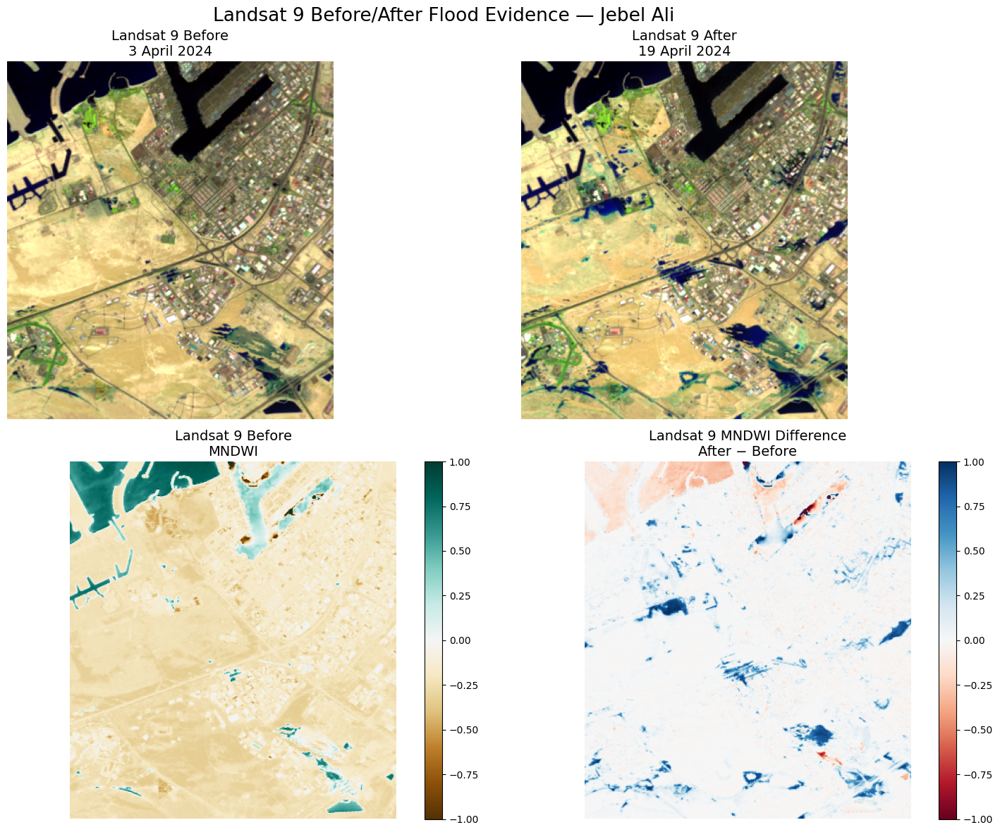

Landsat 9 figure saved:
/content/dimensions3_project/outputs/landsat9_before_after_analysis.png

Interpretation:
- The false-colour images provide visual before/after comparison.
- MNDWI highlights water-like surface responses.
- Landsat 9 is used as an independent validation source.
- It should not be treated as pixel-perfectly aligned with Sentinel-1 or Sentinel-2 yet.

CELL 7 COMPLETE


In [23]:
# ============================================================
# CELL 7 — LANDSAT 9 VISUALIZATION
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

print("============================================================")
print("LANDSAT 9 IMAGE VISUALIZATION")
print("============================================================")

# ------------------------------------------------------------
# 1. Extract loaded Landsat bands
#
# Band order from Cell 6B:
#   0 = Green
#   1 = Near-infrared
#   2 = SWIR 1
# ------------------------------------------------------------

before_green = landsat_before_cube[0]
before_nir = landsat_before_cube[1]
before_swir = landsat_before_cube[2]

after_green = landsat_after_cube[0]
after_nir = landsat_after_cube[1]
after_swir = landsat_after_cube[2]

# ------------------------------------------------------------
# 2. Create false-colour images
#
# Landsat false colour:
#   Red channel   = SWIR 1
#   Green channel = Near-infrared
#   Blue channel  = Green
#
# Water generally appears dark blue in this combination.
# ------------------------------------------------------------

def create_false_colour(
    green,
    nir,
    swir
):
    image = np.stack(
        [
            swir,
            nir,
            green
        ],
        axis=-1
    )

    valid = image[
        np.isfinite(image)
    ]

    low, high = np.percentile(
        valid,
        [2, 98]
    )

    image = np.clip(
        (image - low)
        / (high - low),
        0,
        1
    )

    return image

before_false_colour = create_false_colour(
    before_green,
    before_nir,
    before_swir
)

after_false_colour = create_false_colour(
    after_green,
    after_nir,
    after_swir
)

# ------------------------------------------------------------
# 3. Calculate Landsat MNDWI
# ------------------------------------------------------------

before_landsat_mndwi = np.divide(
    before_green - before_swir,
    before_green + before_swir,
    out=np.full_like(
        before_green,
        np.nan
    ),
    where=(
        before_green + before_swir
    ) != 0
)

after_landsat_mndwi = np.divide(
    after_green - after_swir,
    after_green + after_swir,
    out=np.full_like(
        after_green,
        np.nan
    ),
    where=(
        after_green + after_swir
    ) != 0
)

landsat_mndwi_difference = (
    after_landsat_mndwi
    - before_landsat_mndwi
)

# ------------------------------------------------------------
# 4. Create Landsat figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 12)
)

axes[0, 0].imshow(
    before_false_colour
)

axes[0, 0].set_title(
    "Landsat 9 Before\n3 April 2024",
    fontsize=14
)

axes[0, 1].imshow(
    after_false_colour
)

axes[0, 1].set_title(
    "Landsat 9 After\n19 April 2024",
    fontsize=14
)

mndwi_before_plot = axes[1, 0].imshow(
    before_landsat_mndwi,
    cmap="BrBG",
    vmin=-1,
    vmax=1
)

axes[1, 0].set_title(
    "Landsat 9 Before\nMNDWI",
    fontsize=14
)

plt.colorbar(
    mndwi_before_plot,
    ax=axes[1, 0],
    fraction=0.046
)

mndwi_difference_plot = axes[1, 1].imshow(
    landsat_mndwi_difference,
    cmap="RdBu",
    vmin=-1,
    vmax=1
)

axes[1, 1].set_title(
    "Landsat 9 MNDWI Difference\nAfter − Before",
    fontsize=14
)

plt.colorbar(
    mndwi_difference_plot,
    ax=axes[1, 1],
    fraction=0.046
)

for axis in axes.ravel():
    axis.axis("off")

plt.suptitle(
    "Landsat 9 Before/After Flood Evidence — Jebel Ali",
    fontsize=19
)

plt.tight_layout()

landsat_figure_path = os.path.join(
    OUTPUT_DIR,
    "landsat9_before_after_analysis.png"
)

plt.savefig(
    landsat_figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Landsat 9 figure saved:")
print(landsat_figure_path)

print("\nInterpretation:")
print("- The false-colour images provide visual before/after comparison.")
print("- MNDWI highlights water-like surface responses.")
print("- Landsat 9 is used as an independent validation source.")
print("- It should not be treated as pixel-perfectly aligned with Sentinel-1 or Sentinel-2 yet.")

print("\nCELL 7 COMPLETE")

WEATHER DATA COLLECTION
Requesting NASA POWER weather data...

Weather data collected:


,date,precipitation_mm,temperature_c,wind_speed_m_s,latitude,longitude,source
0,2024-04-01,0.01,23.24,4.19,24.98,55.05,NASA POWER
1,2024-04-02,0.01,23.52,4.11,24.98,55.05,NASA POWER
2,2024-04-03,0.00,24.31,3.45,24.98,55.05,NASA POWER
3,2024-04-04,0.00,23.94,4.52,24.98,55.05,NASA POWER
4,2024-04-05,0.02,23.78,3.59,24.98,55.05,NASA POWER
5,2024-04-06,0.00,23.91,3.40,24.98,55.05,NASA POWER
6,2024-04-07,0.00,25.03,2.72,24.98,55.05,NASA POWER
7,2024-04-08,0.00,26.46,2.49,24.98,55.05,NASA POWER
8,2024-04-09,0.00,26.83,3.36,24.98,55.05,NASA POWER
9,2024-04-10,0.08,26.15,4.66,24.98,55.05,NASA POWER



Rainfall summary:
Peak daily rainfall: 53.39 mm
Peak rainfall date: 2024-04-16


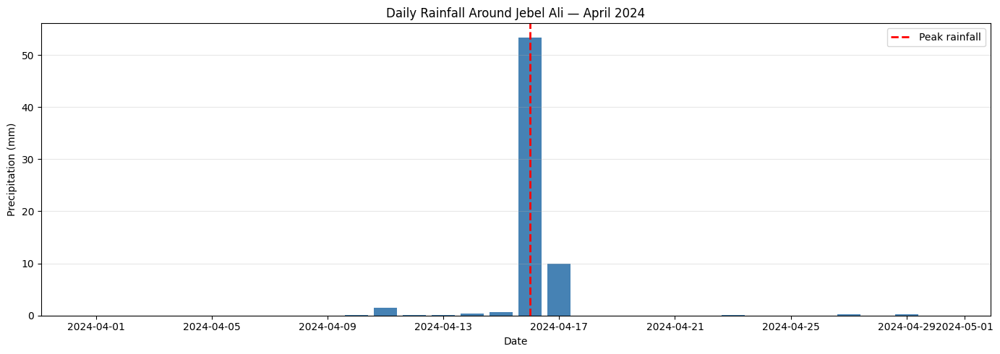


Weather files saved:
- /content/dimensions3_project/packets/weather/jebel_ali_weather_april_2024.csv
- /content/dimensions3_project/packets/weather/weather_metadata.json
- /content/dimensions3_project/outputs/weather_rainfall_april_2024.png

CELL 8 COMPLETE


In [24]:
# ============================================================
# CELL 8 — WEATHER DATA PACKET
# ============================================================

import os
import json
import requests
import pandas as pd
import matplotlib.pyplot as plt

print("============================================================")
print("WEATHER DATA COLLECTION")
print("============================================================")

# Approximate Jebel Ali coordinate
LATITUDE = 24.98
LONGITUDE = 55.05

# NASA POWER daily weather API
POWER_URL = (
    "https://power.larc.nasa.gov/api/temporal/daily/point"
)

parameters = {
    "parameters": "PRECTOTCORR,T2M,WS10M",
    "community": "AG",
    "longitude": LONGITUDE,
    "latitude": LATITUDE,
    "start": "20240401",
    "end": "20240430",
    "format": "JSON"
}

print("Requesting NASA POWER weather data...")

response = requests.get(
    POWER_URL,
    params=parameters,
    timeout=60
)

response.raise_for_status()

weather_json = response.json()
weather_values = weather_json[
    "properties"
]["parameter"]

# ------------------------------------------------------------
# Create weather table
# ------------------------------------------------------------

weather_df = pd.DataFrame({
    "date": list(
        weather_values["PRECTOTCORR"].keys()
    ),
    "precipitation_mm": list(
        weather_values["PRECTOTCORR"].values()
    ),
    "temperature_c": list(
        weather_values["T2M"].values()
    ),
    "wind_speed_m_s": list(
        weather_values["WS10M"].values()
    )
})

weather_df["date"] = pd.to_datetime(
    weather_df["date"]
)

weather_df["latitude"] = LATITUDE
weather_df["longitude"] = LONGITUDE
weather_df["source"] = "NASA POWER"

# ------------------------------------------------------------
# Identify the rainfall peak
# ------------------------------------------------------------

peak_index = weather_df[
    "precipitation_mm"
].idxmax()

peak_rainfall = float(
    weather_df.loc[
        peak_index,
        "precipitation_mm"
    ]
)

peak_date = weather_df.loc[
    peak_index,
    "date"
]

print("\nWeather data collected:")
display(weather_df)

print("\nRainfall summary:")
print(
    "Peak daily rainfall:",
    peak_rainfall,
    "mm"
)

print(
    "Peak rainfall date:",
    peak_date.date()
)

# ------------------------------------------------------------
# Save weather packet
# ------------------------------------------------------------

weather_csv_path = os.path.join(
    WEATHER_DIR,
    "jebel_ali_weather_april_2024.csv"
)

weather_df.to_csv(
    weather_csv_path,
    index=False
)

weather_metadata = {
    "packet": "weather",
    "source": "NASA POWER",
    "latitude": LATITUDE,
    "longitude": LONGITUDE,
    "period": "2024-04-01 to 2024-04-30",
    "variables": {
        "PRECTOTCORR": "Precipitation in mm",
        "T2M": "Temperature in Celsius",
        "WS10M": "Wind speed at 10 m in m/s"
    },
    "peak_rainfall_mm": peak_rainfall,
    "peak_rainfall_date": str(
        peak_date.date()
    ),
    "note": (
        "NASA POWER is gridded supporting data. "
        "NCM station data can be added later for local validation."
    )
}

weather_metadata_path = os.path.join(
    WEATHER_DIR,
    "weather_metadata.json"
)

with open(
    weather_metadata_path,
    "w"
) as file:
    json.dump(
        weather_metadata,
        file,
        indent=2
    )

# ------------------------------------------------------------
# Create a rainfall plot
# ------------------------------------------------------------

plt.figure(
    figsize=(14, 5)
)

plt.bar(
    weather_df["date"],
    weather_df["precipitation_mm"],
    color="steelblue"
)

plt.axvline(
    peak_date,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Peak rainfall"
)

plt.title(
    "Daily Rainfall Around Jebel Ali — April 2024"
)

plt.xlabel("Date")
plt.ylabel("Precipitation (mm)")
plt.ylim(bottom=0)
plt.grid(
    axis="y",
    alpha=0.3
)
plt.legend()
plt.tight_layout()

weather_figure_path = os.path.join(
    OUTPUT_DIR,
    "weather_rainfall_april_2024.png"
)

plt.savefig(
    weather_figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nWeather files saved:")
print("-", weather_csv_path)
print("-", weather_metadata_path)
print("-", weather_figure_path)

print("\nCELL 8 COMPLETE")

REPORTS AND EXTERNAL EVIDENCE
Evidence records collected: 6


,date,source_type,source_name,location,confidence
0,2024-04-16,Official government news,Emirates News Agency (WAM),United Arab Emirates,High
1,2024-04-16,Meteorological warning,Aletihad reporting NCM,United Arab Emirates,High
2,2024-04-24,Government response,Dubai Government Media Portal,"Dubai, UAE",High
3,2024-04-28,Infrastructure response,Emirates News Agency (WAM),United Arab Emirates,High
4,2024-04-16,Independent satellite evidence,NASA Earth Observatory,United Arab Emirates,High
5,2024-04-22,Landsat reference,NASA Earth Observatory via SciTechDaily,"Jebel Ali, Dubai, UAE",High


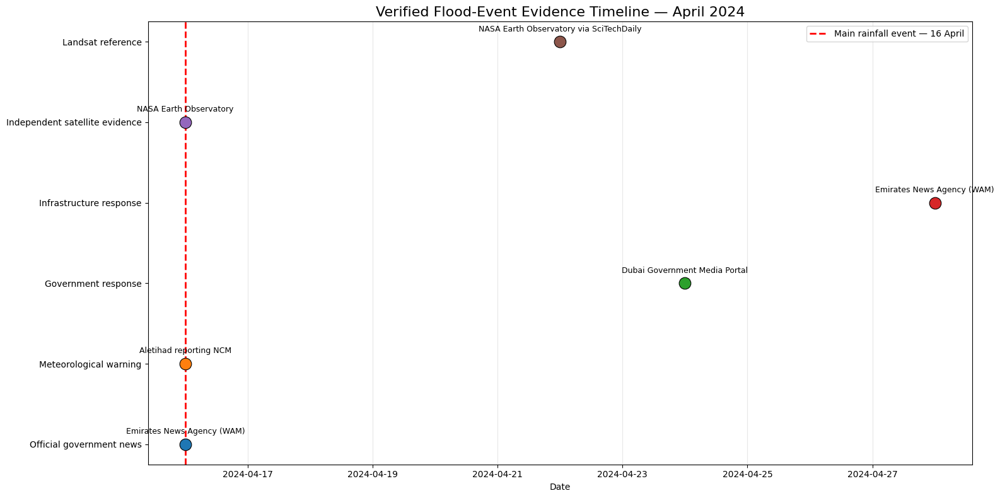

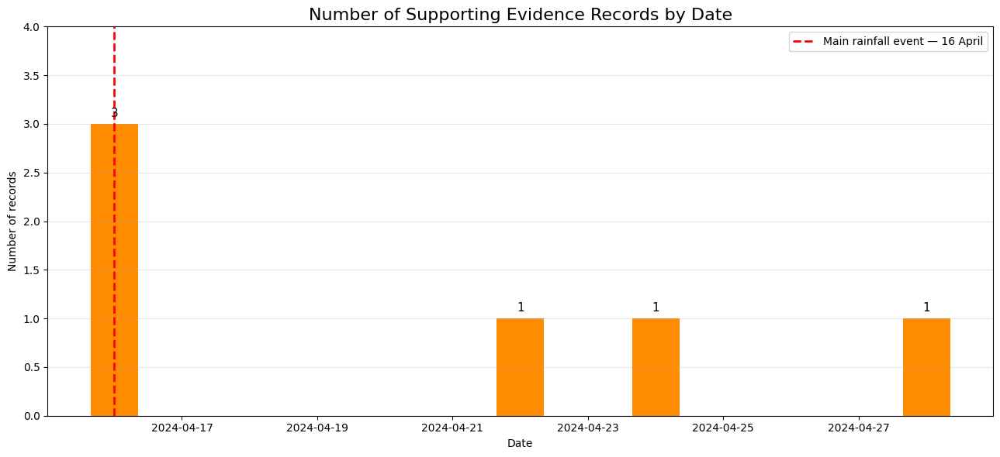


Evidence packet saved:
- /content/dimensions3_project/packets/reports/verified_event_evidence.csv
- /content/dimensions3_project/packets/reports/verified_event_evidence.json

Visualizations saved:
- /content/dimensions3_project/outputs/verified_event_evidence_timeline.png
- /content/dimensions3_project/outputs/evidence_records_by_date.png

Interpretation:
The timeline shows the sequence of warnings, satellite evidence, Landsat reference imagery, and government responses.
The date chart shows that 16 April has the strongest concentration of independent event evidence.
These records validate event timing and support the satellite analysis, but they are not pixel-level flood labels.

CELL 9 COMPLETE


In [25]:
# ============================================================
# CELL 9 — REPORTS, EXTERNAL EVIDENCE, AND VISUALIZATIONS
# ============================================================

import os
import json
import pandas as pd
import matplotlib.pyplot as plt

print("============================================================")
print("REPORTS AND EXTERNAL EVIDENCE")
print("============================================================")

# ------------------------------------------------------------
# 1. Create verified evidence records
# ------------------------------------------------------------

evidence_records = [
    {
        "date": "2024-04-16",
        "source_type": "Official government news",
        "source_name": "Emirates News Agency (WAM)",
        "description": "Exceptional UAE rainfall event reported.",
        "location": "United Arab Emirates",
        "confidence": "High",
        "url": (
            "https://www.wam.ae/en/article/"
            "13vbuq9-uae-witnesses-largest-rainfall-over-past-years"
        )
    },
    {
        "date": "2024-04-16",
        "source_type": "Meteorological warning",
        "source_name": "Aletihad reporting NCM",
        "description": "Heavy rain, thunderstorms, and flood warnings.",
        "location": "United Arab Emirates",
        "confidence": "High",
        "url": (
            "https://en.aletihad.ae/news/uae/"
            "4479196/ncm-issues-weather-condition-update"
        )
    },
    {
        "date": "2024-04-24",
        "source_type": "Government response",
        "source_name": "Dubai Government Media Portal",
        "description": "Response to rain-damaged homes and communities.",
        "location": "Dubai, UAE",
        "confidence": "High",
        "url": (
            "https://pddportalstg.dubai.gov.ae/en/"
            "media-listing/news-events/"
            "cabinet-allocates-aed2-billion-to-stand-by-"
            "uae-citizens-with-rain-damaged-homes/"
        )
    },
    {
        "date": "2024-04-28",
        "source_type": "Infrastructure response",
        "source_name": "Emirates News Agency (WAM)",
        "description": "Flood-damage assessment committee established.",
        "location": "United Arab Emirates",
        "confidence": "High",
        "url": (
            "https://www.wam.ae/en/article/"
            "13vzfkm-uae-committee-tasked-with-assessing-"
            "flood-damage"
        )
    },
    {
        "date": "2024-04-16",
        "source_type": "Independent satellite evidence",
        "source_name": "NASA Earth Observatory",
        "description": "Satellite documentation of widespread UAE flooding.",
        "location": "United Arab Emirates",
        "confidence": "High",
        "url": (
            "https://science.nasa.gov/earth/"
            "earth-observatory/deluge-in-the-united-arab-emirates-152703/"
        )
    },
    {
        "date": "2024-04-22",
        "source_type": "Landsat reference",
        "source_name": "NASA Earth Observatory via SciTechDaily",
        "description": (
            "Landsat 9 before/after imagery shows water "
            "accumulation around Jebel Ali."
        ),
        "location": "Jebel Ali, Dubai, UAE",
        "confidence": "High",
        "url": (
            "https://scitechdaily.com/"
            "satellite-images-capture-extraordinary-flooding-"
            "in-the-united-arab-emirates/"
        )
    }
]

evidence_df = pd.DataFrame(
    evidence_records
)

evidence_df["date"] = pd.to_datetime(
    evidence_df["date"]
)

# ------------------------------------------------------------
# 2. Save evidence packet
# ------------------------------------------------------------

evidence_csv_path = os.path.join(
    REPORTS_DIR,
    "verified_event_evidence.csv"
)

evidence_json_path = os.path.join(
    REPORTS_DIR,
    "verified_event_evidence.json"
)

evidence_df.to_csv(
    evidence_csv_path,
    index=False
)

evidence_df.to_json(
    evidence_json_path,
    orient="records",
    indent=2,
    date_format="iso"
)

print("Evidence records collected:", len(evidence_df))

# ------------------------------------------------------------
# 3. Display evidence table
# ------------------------------------------------------------

display(
    evidence_df[
        [
            "date",
            "source_type",
            "source_name",
            "location",
            "confidence"
        ]
    ]
)

# ------------------------------------------------------------
# 4. Create verified evidence timeline
# ------------------------------------------------------------

source_types = list(
    evidence_df["source_type"].unique()
)

source_positions = {
    source_type: index
    for index, source_type
    in enumerate(source_types)
}

fig, axis = plt.subplots(
    figsize=(16, 8)
)

colors = plt.cm.tab10(
    range(len(source_types))
)

for _, row in evidence_df.iterrows():

    y_position = source_positions[
        row["source_type"]
    ]

    axis.scatter(
        row["date"],
        y_position,
        s=180,
        color=colors[y_position],
        edgecolor="black",
        linewidth=0.8,
        zorder=3
    )

    axis.annotate(
        row["source_name"],
        (
            row["date"],
            y_position
        ),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

event_date = pd.Timestamp(
    "2024-04-16"
)

axis.axvline(
    event_date,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Main rainfall event — 16 April"
)

axis.set_yticks(
    list(source_positions.values())
)

axis.set_yticklabels(
    list(source_positions.keys())
)

axis.set_xlabel("Date")

axis.set_title(
    "Verified Flood-Event Evidence Timeline — April 2024",
    fontsize=16
)

axis.grid(
    axis="x",
    alpha=0.3
)

axis.legend()

plt.tight_layout()

timeline_path = os.path.join(
    OUTPUT_DIR,
    "verified_event_evidence_timeline.png"
)

plt.savefig(
    timeline_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. Create evidence-by-date visualization
# ------------------------------------------------------------
#
# This replaces the previous source-count chart.
# It shows how many independent records support each date.

evidence_by_date = (
    evidence_df
    .groupby("date")
    .size()
    .reset_index(
        name="evidence_count"
    )
)

plt.figure(
    figsize=(13, 6)
)

bars = plt.bar(
    evidence_by_date["date"],
    evidence_by_date["evidence_count"],
    color="darkorange",
    width=0.7
)

plt.axvline(
    event_date,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Main rainfall event — 16 April"
)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.05,
        str(int(height)),
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.title(
    "Number of Supporting Evidence Records by Date",
    fontsize=16
)

plt.xlabel("Date")
plt.ylabel("Number of records")
plt.ylim(
    bottom=0,
    top=evidence_by_date["evidence_count"].max() + 1
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.legend()
plt.tight_layout()

date_evidence_path = os.path.join(
    OUTPUT_DIR,
    "evidence_records_by_date.png"
)

plt.savefig(
    date_evidence_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 6. Final summary
# ------------------------------------------------------------

print("\nEvidence packet saved:")
print("-", evidence_csv_path)
print("-", evidence_json_path)

print("\nVisualizations saved:")
print("-", timeline_path)
print("-", date_evidence_path)

print("\nInterpretation:")
print(
    "The timeline shows the sequence of warnings, satellite "
    "evidence, Landsat reference imagery, and government responses."
)

print(
    "The date chart shows that 16 April has the strongest "
    "concentration of independent event evidence."
)

print(
    "These records validate event timing and support the satellite "
    "analysis, but they are not pixel-level flood labels."
)

print("\nCELL 9 COMPLETE")

SENTINEL-1 CHANGE ANALYSIS
Before VV: /content/dimensions3_project/packets/sentinel1/raw_products/2024-04-12_before/2024-04-12_before/measurement/s1a-iw-grd-vv-20240412t142512-20240412t142537-053402-067a39-001.tiff
Before VH: /content/dimensions3_project/packets/sentinel1/raw_products/2024-04-12_before/2024-04-12_before/measurement/s1a-iw-grd-vh-20240412t142512-20240412t142537-053402-067a39-002.tiff
After VV : /content/dimensions3_project/packets/sentinel1/raw_products/2024-04-24_after/2024-04-24_after/measurement/s1a-iw-grd-vv-20240424t142514-20240424t142539-053577-068115-001.tiff
After VH : /content/dimensions3_project/packets/sentinel1/raw_products/2024-04-24_after/2024-04-24_after/measurement/s1a-iw-grd-vh-20240424t142514-20240424t142539-053577-068115-002.tiff

Reading reduced-resolution previews...
s1a-iw-grd-vv-20240412t142512-20240412t142537-053402-067a39-001.tiff | min: 0.0 | max: 27095.0
  Detected linear radar power; converting to dB.
s1a-iw-grd-vh-20240412t142512-20240412t14

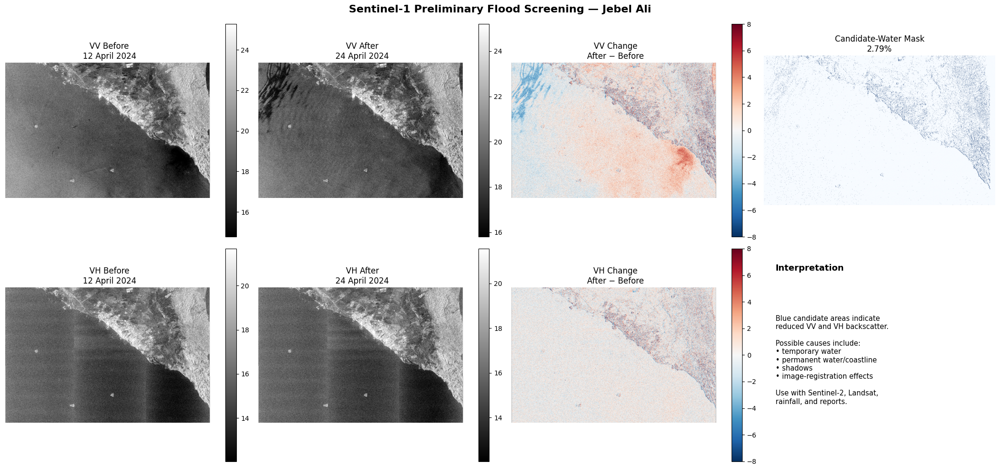


SENTINEL-1 ANALYSIS COMPLETE
Figure saved: /content/dimensions3_project/outputs/sentinel1_before_after_change_analysis.png
Arrays saved: /content/dimensions3_project/packets/sentinel1/sentinel1_change_arrays.npz
Summary saved: /content/dimensions3_project/packets/sentinel1/sentinel1_change_summary.json


In [26]:
# ============================================================
# CELL 10 — MEMORY-SAFE SENTINEL-1 CHANGE ANALYSIS
# ============================================================

import os
import glob
import json
import numpy as np
import rasterio
import matplotlib.pyplot as plt

print("=" * 60)
print("SENTINEL-1 CHANGE ANALYSIS")
print("=" * 60)

# ------------------------------------------------------------
# 1. Locate Sentinel-1 VV and VH files
# ------------------------------------------------------------

s1_base = "/content/dimensions3_project/packets/sentinel1/raw_products"

before_files = glob.glob(
    f"{s1_base}/2024-04-12_before/**/*.tiff",
    recursive=True
)

after_files = glob.glob(
    f"{s1_base}/2024-04-24_after/**/*.tiff",
    recursive=True
)

def find_polarization(files, polarization):
    matches = [
        f for f in files
        if polarization in os.path.basename(f).lower()
    ]

    if not matches:
        raise FileNotFoundError(
            f"No {polarization.upper()} TIFF found."
        )

    return matches[0]

before_vv_path = find_polarization(before_files, "vv")
before_vh_path = find_polarization(before_files, "vh")
after_vv_path = find_polarization(after_files, "vv")
after_vh_path = find_polarization(after_files, "vh")

print("Before VV:", before_vv_path)
print("Before VH:", before_vh_path)
print("After VV :", after_vv_path)
print("After VH :", after_vh_path)

# ------------------------------------------------------------
# 2. Read reduced-resolution radar data
# ------------------------------------------------------------

MAX_SIZE = 1200

def read_sentinel1_safe(path, max_size=MAX_SIZE):

    with rasterio.open(path) as src:

        scale = min(
            1.0,
            max_size / src.width,
            max_size / src.height
        )

        out_width = max(1, int(src.width * scale))
        out_height = max(1, int(src.height * scale))

        data = src.read(
            1,
            out_shape=(1, out_height, out_width),
            resampling=rasterio.enums.Resampling.nearest
        ).astype("float32")

    valid = data[np.isfinite(data)]

    if len(valid) == 0:
        raise ValueError(f"No valid values found in {path}")

    minimum = float(np.nanmin(valid))
    maximum = float(np.nanmax(valid))

    print(
        os.path.basename(path),
        "| min:", round(minimum, 3),
        "| max:", round(maximum, 3)
    )

    # Detect whether data are already in dB
    if maximum <= 0:
        print("  Detected existing dB values.")
        data_db = data

    # Otherwise convert positive radar power to dB
    else:
        print("  Detected linear radar power; converting to dB.")
        data[data <= 0] = np.nan
        data_db = 10 * np.log10(data)

    return data_db

print("\nReading reduced-resolution previews...")

before_vv = read_sentinel1_safe(before_vv_path)
before_vh = read_sentinel1_safe(before_vh_path)
after_vv = read_sentinel1_safe(after_vv_path)
after_vh = read_sentinel1_safe(after_vh_path)

# ------------------------------------------------------------
# 3. Match image dimensions
# ------------------------------------------------------------

rows = min(
    before_vv.shape[0],
    before_vh.shape[0],
    after_vv.shape[0],
    after_vh.shape[0]
)

cols = min(
    before_vv.shape[1],
    before_vh.shape[1],
    after_vv.shape[1],
    after_vh.shape[1]
)

before_vv = before_vv[:rows, :cols]
before_vh = before_vh[:rows, :cols]
after_vv = after_vv[:rows, :cols]
after_vh = after_vh[:rows, :cols]

print("\nReduced image shape:", before_vv.shape)

# ------------------------------------------------------------
# 4. Calculate VV/VH change
# ------------------------------------------------------------

vv_change = after_vv - before_vv
vh_change = after_vh - before_vh

# Preliminary water signal:
# reduced backscatter in both VV and VH
candidate_water = (
    (vv_change < -3.0) &
    (vh_change < -2.0) &
    np.isfinite(vv_change) &
    np.isfinite(vh_change)
)

valid_pixels = int(np.sum(np.isfinite(vv_change)))
candidate_pixels = int(np.sum(candidate_water))

candidate_percentage = (
    100 * candidate_pixels / valid_pixels
    if valid_pixels > 0 else 0
)

print("\nSentinel-1 change summary")
print("Valid pixels:", valid_pixels)
print("Candidate-water pixels:", candidate_pixels)
print(
    "Candidate-water percentage:",
    round(candidate_percentage, 2),
    "%"
)

# ------------------------------------------------------------
# 5. Use percentile display limits
# ------------------------------------------------------------

def display_limits(image):
    valid = image[np.isfinite(image)]

    if len(valid) == 0:
        return -30, 5

    low, high = np.nanpercentile(valid, [2, 98])

    if low == high:
        low -= 1
        high += 1

    return float(low), float(high)

vv_before_min, vv_before_max = display_limits(before_vv)
vv_after_min, vv_after_max = display_limits(after_vv)
vh_before_min, vh_before_max = display_limits(before_vh)
vh_after_min, vh_after_max = display_limits(after_vh)

# ------------------------------------------------------------
# 6. Create complete visualization
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 4, figsize=(21, 10))

# VV Before
im1 = axes[0, 0].imshow(
    before_vv,
    cmap="gray",
    vmin=vv_before_min,
    vmax=vv_before_max
)
axes[0, 0].set_title("VV Before\n12 April 2024")
axes[0, 0].axis("off")
plt.colorbar(im1, ax=axes[0, 0], fraction=0.046)

# VV After
im2 = axes[0, 1].imshow(
    after_vv,
    cmap="gray",
    vmin=vv_after_min,
    vmax=vv_after_max
)
axes[0, 1].set_title("VV After\n24 April 2024")
axes[0, 1].axis("off")
plt.colorbar(im2, ax=axes[0, 1], fraction=0.046)

# VV Change
im3 = axes[0, 2].imshow(
    vv_change,
    cmap="RdBu_r",
    vmin=-8,
    vmax=8
)
axes[0, 2].set_title("VV Change\nAfter − Before")
axes[0, 2].axis("off")
plt.colorbar(im3, ax=axes[0, 2], fraction=0.046)

# Candidate-water mask
axes[0, 3].imshow(
    candidate_water,
    cmap="Blues",
    vmin=0,
    vmax=1
)
axes[0, 3].set_title(
    "Candidate-Water Mask\n"
    f"{candidate_percentage:.2f}%"
)
axes[0, 3].axis("off")

# VH Before
im4 = axes[1, 0].imshow(
    before_vh,
    cmap="gray",
    vmin=vh_before_min,
    vmax=vh_before_max
)
axes[1, 0].set_title("VH Before\n12 April 2024")
axes[1, 0].axis("off")
plt.colorbar(im4, ax=axes[1, 0], fraction=0.046)

# VH After
im5 = axes[1, 1].imshow(
    after_vh,
    cmap="gray",
    vmin=vh_after_min,
    vmax=vh_after_max
)
axes[1, 1].set_title("VH After\n24 April 2024")
axes[1, 1].axis("off")
plt.colorbar(im5, ax=axes[1, 1], fraction=0.046)

# VH Change
im6 = axes[1, 2].imshow(
    vh_change,
    cmap="RdBu_r",
    vmin=-8,
    vmax=8
)
axes[1, 2].set_title("VH Change\nAfter − Before")
axes[1, 2].axis("off")
plt.colorbar(im6, ax=axes[1, 2], fraction=0.046)

# Explanation
axes[1, 3].axis("off")
axes[1, 3].text(
    0.05,
    0.88,
    "Interpretation",
    fontsize=13,
    fontweight="bold"
)
axes[1, 3].text(
    0.05,
    0.68,
    "Blue candidate areas indicate\n"
    "reduced VV and VH backscatter.\n\n"
    "Possible causes include:\n"
    "• temporary water\n"
    "• permanent water/coastline\n"
    "• shadows\n"
    "• image-registration effects\n\n"
    "Use with Sentinel-2, Landsat,\n"
    "rainfall, and reports.",
    fontsize=10.5,
    va="top"
)

plt.suptitle(
    "Sentinel-1 Preliminary Flood Screening — Jebel Ali",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# ------------------------------------------------------------
# 7. Save outputs
# ------------------------------------------------------------

output_dir = "/content/dimensions3_project/outputs"
packet_dir = "/content/dimensions3_project/packets/sentinel1"

os.makedirs(output_dir, exist_ok=True)
os.makedirs(packet_dir, exist_ok=True)

figure_path = os.path.join(
    output_dir,
    "sentinel1_before_after_change_analysis.png"
)

plt.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

arrays_path = os.path.join(
    packet_dir,
    "sentinel1_change_arrays.npz"
)

np.savez_compressed(
    arrays_path,
    before_vv=before_vv,
    after_vv=after_vv,
    before_vh=before_vh,
    after_vh=after_vh,
    vv_change=vv_change,
    vh_change=vh_change,
    candidate_water=candidate_water
)

summary = {
    "before_date": "2024-04-12",
    "after_date": "2024-04-24",
    "preview_shape": list(before_vv.shape),
    "candidate_water_pixels": candidate_pixels,
    "valid_pixels": valid_pixels,
    "candidate_percentage": round(
        float(candidate_percentage), 4
    ),
    "vv_threshold_db": -3.0,
    "vh_threshold_db": -2.0,
    "status": "Preliminary reduced-resolution screening",
    "limitation": (
        "Calibration, terrain correction, and georeferenced "
        "area calculation are still required."
    ),
    "figure_path": figure_path,
    "arrays_path": arrays_path
}

summary_path = os.path.join(
    packet_dir,
    "sentinel1_change_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 60)
print("SENTINEL-1 ANALYSIS COMPLETE")
print("=" * 60)
print("Figure saved:", figure_path)
print("Arrays saved:", arrays_path)
print("Summary saved:", summary_path)

MULTI-SOURCE FLOOD EVIDENCE FUSION
Sentinel-1 mask loaded: (777, 1200)
Landsat 9 mask loaded: (374, 341)
Sentinel-2 water-change mask loaded: (562, 514)

Spatial fusion summary
High-agreement candidate area: 0.71 %
Sentinel-1 candidate percentage: 2.7 %
Landsat candidate percentage: 4.05 %
Sentinel-2 candidate percentage: 0.85 %

Weather evidence
Peak rainfall: 53.39 mm
Peak rainfall date: 2024-04-16
Rainfall support score: 1.0

Supporting evidence
Evidence records: 6
Report support score: 1.0

FINAL PRELIMINARY FLOOD SCREENING
Screening label: MEDIUM
Combined score: 0.571
High-agreement candidate area: 0.71 %
Peak rainfall: 53.39 mm
Supporting records: 6


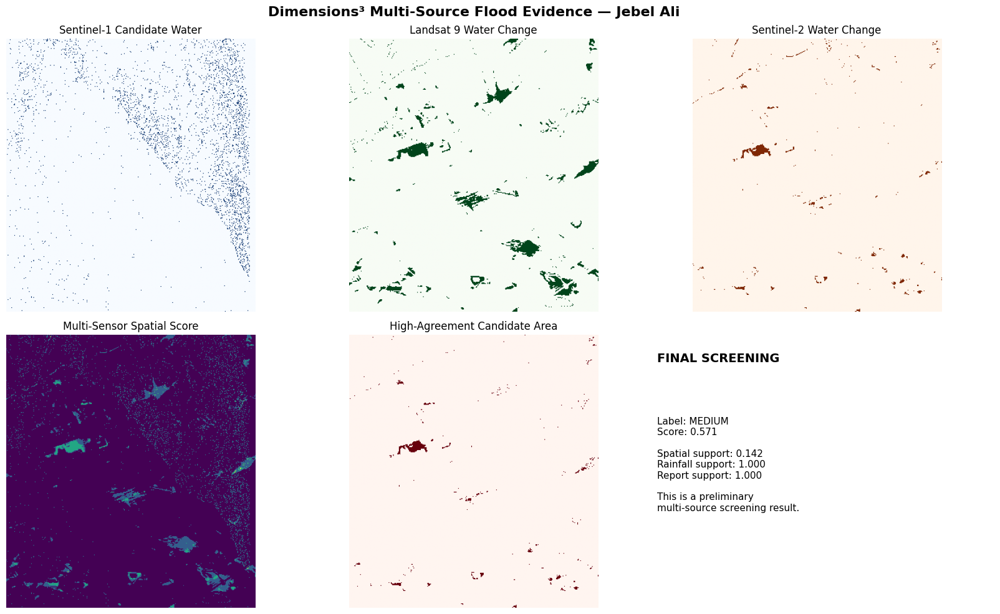


FUSION COMPLETE
Fusion figure saved: /content/dimensions3_project/outputs/multi_source_flood_fusion.png
Fusion summary saved: /content/dimensions3_project/outputs/multi_source_flood_fusion_summary.json


In [27]:
# ============================================================
# CELL 11 — MULTI-SOURCE FLOOD EVIDENCE FUSION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import zoom

print("=" * 70)
print("MULTI-SOURCE FLOOD EVIDENCE FUSION")
print("=" * 70)

BASE_DIR = "/content/dimensions3_project"
OUTPUT_DIR = f"{BASE_DIR}/outputs"
PACKETS_DIR = f"{BASE_DIR}/packets"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Load Sentinel-1 candidate-water mask
# ------------------------------------------------------------

s1_npz_path = (
    f"{PACKETS_DIR}/sentinel1/"
    "sentinel1_change_arrays.npz"
)

s1_data = np.load(s1_npz_path)

s1_mask = s1_data["candidate_water"].astype(bool)

print("Sentinel-1 mask loaded:", s1_mask.shape)

# ------------------------------------------------------------
# 2. Load Landsat 9 reflectance arrays
# ------------------------------------------------------------

landsat_npz_path = (
    f"{PACKETS_DIR}/landsat9/"
    "landsat9_reflectance_arrays.npz"
)

landsat_data = np.load(landsat_npz_path)

landsat_before = landsat_data["before"]
landsat_after = landsat_data["after"]

# Expected order:
# index 0 = green
# index 1 = NIR
# index 2 = SWIR1

green_before = landsat_before[0]
swir_before = landsat_before[2]

green_after = landsat_after[0]
swir_after = landsat_after[2]

def calculate_mndwi(green, swir):
    denominator = green + swir
    denominator = np.where(
        denominator == 0,
        np.nan,
        denominator
    )
    return (green - swir) / denominator

mndwi_before = calculate_mndwi(
    green_before,
    swir_before
)

mndwi_after = calculate_mndwi(
    green_after,
    swir_after
)

mndwi_change = mndwi_after - mndwi_before

# Positive MNDWI change suggests newly water-like surfaces.
landsat_mask = (
    (mndwi_after > 0.20) &
    (mndwi_change > 0.10) &
    np.isfinite(mndwi_change)
)

print("Landsat 9 mask loaded:", landsat_mask.shape)

# ------------------------------------------------------------
# 3. Load Sentinel-2 water-change evidence if available
# ------------------------------------------------------------

sentinel2_mask = None

if "sentinel2_stack" in globals():

    try:
        stack = sentinel2_stack

        # Read Sentinel-2 bands
        b03_before = stack.sel(
            time=stack.time.values[0],
            band="B03"
        ).values.astype("float32")

        b11_before = stack.sel(
            time=stack.time.values[0],
            band="B11"
        ).values.astype("float32")

        b03_after = stack.sel(
            time=stack.time.values[1],
            band="B03"
        ).values.astype("float32")

        b11_after = stack.sel(
            time=stack.time.values[1],
            band="B11"
        ).values.astype("float32")

        s2_mndwi_before = calculate_mndwi(
            b03_before,
            b11_before
        )

        s2_mndwi_after = calculate_mndwi(
            b03_after,
            b11_after
        )

        s2_mndwi_change = (
            s2_mndwi_after - s2_mndwi_before
        )

        sentinel2_mask = (
            (s2_mndwi_after > 0.20) &
            (s2_mndwi_change > 0.10) &
            np.isfinite(s2_mndwi_change)
        )

        print(
            "Sentinel-2 water-change mask loaded:",
            sentinel2_mask.shape
        )

    except Exception as error:
        print("Sentinel-2 mask could not be created:", error)

else:
    print(
        "Sentinel-2 stack is not available in memory."
    )
    print(
        "Fusion will continue using Sentinel-1 and Landsat 9."
    )

# ------------------------------------------------------------
# 4. Resize masks to a common grid
# ------------------------------------------------------------

target_shape = landsat_mask.shape

def resize_mask(mask, target_shape):
    if mask is None:
        return np.zeros(target_shape, dtype=bool)

    row_scale = target_shape[0] / mask.shape[0]
    col_scale = target_shape[1] / mask.shape[1]

    resized = zoom(
        mask.astype("float32"),
        (row_scale, col_scale),
        order=0
    )

    resized = resized[
        :target_shape[0],
        :target_shape[1]
    ]

    # Correct possible one-pixel mismatch
    output = np.zeros(target_shape, dtype=bool)

    rows = min(output.shape[0], resized.shape[0])
    cols = min(output.shape[1], resized.shape[1])

    output[:rows, :cols] = resized[:rows, :cols] > 0.5

    return output

s1_common = resize_mask(
    s1_mask,
    target_shape
)

s2_common = resize_mask(
    sentinel2_mask,
    target_shape
)

landsat_common = landsat_mask

# ------------------------------------------------------------
# 5. Calculate spatial agreement
# ------------------------------------------------------------

spatial_score = (
    0.40 * s1_common.astype(float) +
    0.30 * s2_common.astype(float) +
    0.30 * landsat_common.astype(float)
)

# Stronger evidence requires agreement between sources.
high_agreement_mask = spatial_score >= 0.60

candidate_area_percentage = (
    100 * np.mean(high_agreement_mask)
)

print("\nSpatial fusion summary")
print(
    "High-agreement candidate area:",
    round(candidate_area_percentage, 2),
    "%"
)

print(
    "Sentinel-1 candidate percentage:",
    round(100 * np.mean(s1_common), 2),
    "%"
)

print(
    "Landsat candidate percentage:",
    round(100 * np.mean(landsat_common), 2),
    "%"
)

print(
    "Sentinel-2 candidate percentage:",
    round(100 * np.mean(s2_common), 2),
    "%"
)

# ------------------------------------------------------------
# 6. Add rainfall evidence
# ------------------------------------------------------------

weather_path = (
    f"{BASE_DIR}/packets/weather/"
    "jebel_ali_weather_april_2024.csv"
)

rainfall_score = 0.0
peak_rainfall = None
peak_rainfall_date = None

if os.path.exists(weather_path):

    weather = pd.read_csv(weather_path)

    # This is the actual rainfall column in our CSV
    rainfall_column = "precipitation_mm"

    if rainfall_column in weather.columns:

        weather[rainfall_column] = pd.to_numeric(
            weather[rainfall_column],
            errors="coerce"
        )

        peak_index = weather[rainfall_column].idxmax()

        peak_rainfall = float(
            weather.loc[peak_index, rainfall_column]
        )

        peak_rainfall_date = str(
            weather.loc[peak_index, "date"]
        )

        # 50 mm/day or more gives maximum rainfall support
        rainfall_score = min(
            peak_rainfall / 50.0,
            1.0
        )

    else:
        print(
            "Rainfall column not found. Available columns:",
            list(weather.columns)
        )

else:
    print("Weather file not found:", weather_path)

print("\nWeather evidence")
print("Peak rainfall:", peak_rainfall, "mm")
print("Peak rainfall date:", peak_rainfall_date)
print(
    "Rainfall support score:",
    round(rainfall_score, 3)
)

# ------------------------------------------------------------
# 7. Add official/news evidence
# ------------------------------------------------------------

evidence_path = (
    f"{BASE_DIR}/packets/reports/"
    "verified_event_evidence.csv"
)

evidence_score = 0.0
evidence_count = 0

if os.path.exists(evidence_path):

    evidence_table = pd.read_csv(evidence_path)

    evidence_count = len(evidence_table)

    # Six or more independent records receive full support.
    evidence_score = min(
        evidence_count / 6.0,
        1.0
    )

print("\nSupporting evidence")
print("Evidence records:", evidence_count)
print("Report support score:", round(evidence_score, 3))

# ------------------------------------------------------------
# 8. Calculate final transparent confidence score
# ------------------------------------------------------------

spatial_support = min(
    candidate_area_percentage / 5.0,
    1.0
)

final_score = (
    0.50 * spatial_support +
    0.30 * rainfall_score +
    0.20 * evidence_score
)

if final_score >= 0.70:
    screening_label = "HIGH"
elif final_score >= 0.45:
    screening_label = "MEDIUM"
else:
    screening_label = "LOW"

print("\n" + "=" * 70)
print("FINAL PRELIMINARY FLOOD SCREENING")
print("=" * 70)
print("Screening label:", screening_label)
print("Combined score:", round(final_score, 3))
print(
    "High-agreement candidate area:",
    round(candidate_area_percentage, 2),
    "%"
)
print("Peak rainfall:", peak_rainfall, "mm")
print("Supporting records:", evidence_count)

# ------------------------------------------------------------
# 9. Create fusion visualization
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

axes[0, 0].imshow(
    s1_common,
    cmap="Blues",
    vmin=0,
    vmax=1
)
axes[0, 0].set_title("Sentinel-1 Candidate Water")
axes[0, 0].axis("off")

axes[0, 1].imshow(
    landsat_common,
    cmap="Greens",
    vmin=0,
    vmax=1
)
axes[0, 1].set_title("Landsat 9 Water Change")
axes[0, 1].axis("off")

axes[0, 2].imshow(
    s2_common,
    cmap="Oranges",
    vmin=0,
    vmax=1
)
axes[0, 2].set_title("Sentinel-2 Water Change")
axes[0, 2].axis("off")

axes[1, 0].imshow(
    spatial_score,
    cmap="viridis",
    vmin=0,
    vmax=1
)
axes[1, 0].set_title("Multi-Sensor Spatial Score")
axes[1, 0].axis("off")

axes[1, 1].imshow(
    high_agreement_mask,
    cmap="Reds",
    vmin=0,
    vmax=1
)
axes[1, 1].set_title(
    "High-Agreement Candidate Area"
)
axes[1, 1].axis("off")

axes[1, 2].axis("off")
axes[1, 2].text(
    0.05,
    0.90,
    "FINAL SCREENING",
    fontsize=14,
    fontweight="bold"
)
axes[1, 2].text(
    0.05,
    0.70,
    f"Label: {screening_label}\n"
    f"Score: {final_score:.3f}\n\n"
    f"Spatial support: {spatial_support:.3f}\n"
    f"Rainfall support: {rainfall_score:.3f}\n"
    f"Report support: {evidence_score:.3f}\n\n"
    "This is a preliminary\n"
    "multi-source screening result.",
    fontsize=11,
    va="top"
)

plt.suptitle(
    "Dimensions³ Multi-Source Flood Evidence — Jebel Ali",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

fusion_figure_path = (
    f"{OUTPUT_DIR}/multi_source_flood_fusion.png"
)

plt.savefig(
    fusion_figure_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 10. Save final fusion summary
# ------------------------------------------------------------

fusion_summary = {
    "location": "Jebel Ali, Dubai",
    "screening_label": screening_label,
    "combined_score": round(float(final_score), 4),
    "candidate_area_percentage": round(
        float(candidate_area_percentage),
        4
    ),
    "sentinel1_support_percentage": round(
        float(100 * np.mean(s1_common)),
        4
    ),
    "sentinel2_support_percentage": round(
        float(100 * np.mean(s2_common)),
        4
    ),
    "landsat9_support_percentage": round(
        float(100 * np.mean(landsat_common)),
        4
    ),
    "peak_rainfall_mm": peak_rainfall,
    "peak_rainfall_date": peak_rainfall_date,
    "supporting_evidence_count": evidence_count,
    "spatial_support_score": round(
        float(spatial_support),
        4
    ),
    "rainfall_support_score": round(
        float(rainfall_score),
        4
    ),
    "report_support_score": round(
        float(evidence_score),
        4
    ),
    "figure_path": fusion_figure_path,
    "interpretation": (
        "The result is a preliminary screening signal. "
        "High-agreement pixels indicate locations where "
        "multiple satellite sources suggest water-related "
        "surface change. Exact flood extent requires "
        "calibrated, terrain-corrected, georeferenced data "
        "and local validation."
    )
}

fusion_summary_path = (
    f"{OUTPUT_DIR}/multi_source_flood_fusion_summary.json"
)

with open(fusion_summary_path, "w") as f:
    json.dump(fusion_summary, f, indent=2)

print("\n" + "=" * 70)
print("FUSION COMPLETE")
print("=" * 70)
print("Fusion figure saved:", fusion_figure_path)
print("Fusion summary saved:", fusion_summary_path)

ACCURACY IMPROVEMENT AND SOCIAL EVIDENCE

Improved spatial evidence
Permanent-water pixels removed: 9207
Improved high-agreement pixels: 873
Improved candidate area: 0.74 %

Social evidence added: 3
Social evidence table: /content/dimensions3_project/packets/reports/social_media_supporting_evidence.csv

IMPROVED FLOOD SCREENING
Screening label: MEDIUM
Improved combined score: 0.574
Improved high-agreement area: 0.74 %
Peak rainfall: 53.39 mm
Total evidence records: 9


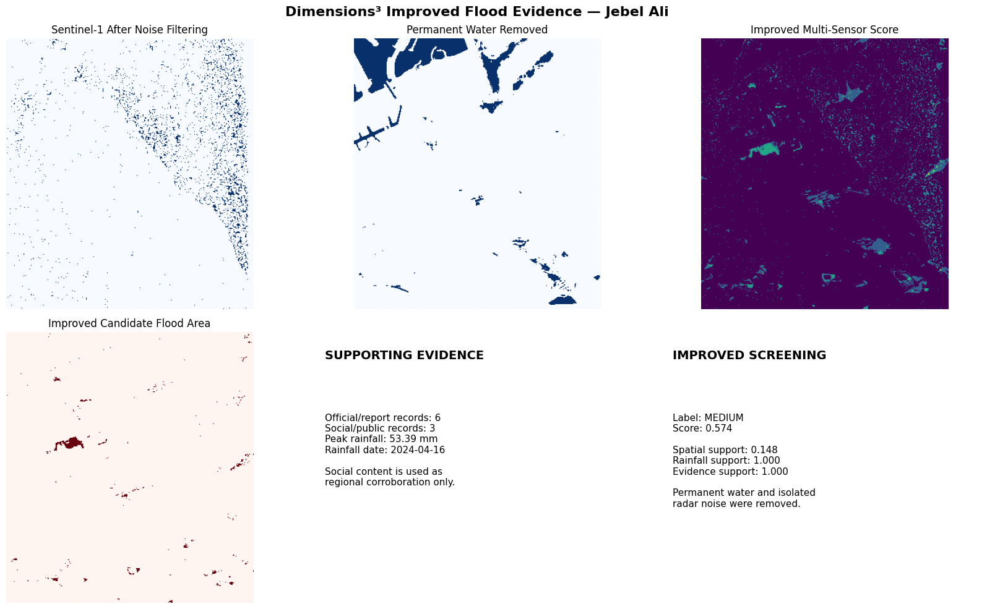


CELL 12 COMPLETE
Improved figure: /content/dimensions3_project/outputs/improved_multi_source_flood_fusion.png
Improved summary: /content/dimensions3_project/outputs/improved_flood_evidence_summary.json
Social evidence CSV: /content/dimensions3_project/packets/reports/social_media_supporting_evidence.csv


In [29]:
# ============================================================
# CELL 12 — ACCURACY IMPROVEMENT + SOCIAL EVIDENCE
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import (
    binary_opening,
    binary_closing,
    binary_fill_holes
)

print("=" * 70)
print("ACCURACY IMPROVEMENT AND SOCIAL EVIDENCE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Remove permanent water and coastline effects
# ------------------------------------------------------------
# The pre-event Landsat MNDWI identifies water already present
# before the rainfall event. These pixels should not be counted
# as newly flooded areas.

permanent_water = (
    np.isfinite(mndwi_before) &
    (mndwi_before > 0.20)
)

land_mask = ~permanent_water

# Resize the land mask to the common fusion grid
permanent_water_common = resize_mask(
    permanent_water,
    target_shape
)

land_mask_common = ~permanent_water_common

# ------------------------------------------------------------
# 2. Apply land mask to all satellite layers
# ------------------------------------------------------------

s1_land = s1_common & land_mask_common
s2_land = s2_common & land_mask_common
landsat_land = landsat_common & land_mask_common

# ------------------------------------------------------------
# 3. Remove isolated radar noise
# ------------------------------------------------------------

# Keep the original Sentinel-1 signal.
# Only remove very small isolated noise clusters.

s1_clean = s1_land.copy()

# Light smoothing without deleting sparse radar detections
s1_clean = binary_closing(
    s1_clean,
    structure=np.ones((2, 2))
)

# ------------------------------------------------------------
# 4. Recalculate multi-sensor agreement
# ------------------------------------------------------------

improved_spatial_score = (
    0.40 * s1_clean.astype(float) +
    0.30 * s2_land.astype(float) +
    0.30 * landsat_land.astype(float)
)

improved_agreement_mask = (
    improved_spatial_score >= 0.60
)

valid_land_pixels = int(
    np.sum(land_mask_common)
)

improved_candidate_pixels = int(
    np.sum(improved_agreement_mask)
)

improved_candidate_percentage = (
    100 * improved_candidate_pixels / valid_land_pixels
    if valid_land_pixels > 0 else 0
)

print("\nImproved spatial evidence")
print(
    "Permanent-water pixels removed:",
    int(np.sum(permanent_water_common))
)
print(
    "Improved high-agreement pixels:",
    improved_candidate_pixels
)
print(
    "Improved candidate area:",
    round(improved_candidate_percentage, 2),
    "%"
)

# ------------------------------------------------------------
# 5. Add social-media and public visual evidence
# ------------------------------------------------------------
# These sources support the occurrence of flooding.
# They are not used as exact pixel-level labels.

social_evidence = [
    {
        "date": "2024-04-16",
        "source": "Public YouTube event video",
        "type": "user-generated video",
        "location": "Dubai, UAE — regional event evidence",
        "url": "https://www.youtube.com/watch?v=ePy0twqwTIw",
        "verification": "timestamped public event content",
        "confidence": "medium",
        "use": "regional corroboration only"
    },
    {
        "date": "2024-04-16",
        "source": "Associated Press event report",
        "type": "news report referencing public updates",
        "location": "Dubai, UAE",
        "url": "https://apnews.com/article/3e838dbc169e52dcd6d11b64f79bdcb7",
        "verification": "professional news organization",
        "confidence": "high",
        "use": "regional event corroboration"
    },
    {
        "date": "2024-04-16",
        "source": "Public social-media flood footage",
        "type": "social-media visual evidence",
        "location": "Dubai, UAE — not confirmed at Jebel Ali pixel level",
        "url": "https://www.youtube.com/watch?v=AWFYkqWej28",
        "verification": "publicly available event compilation",
        "confidence": "medium",
        "use": "regional corroboration only"
    }
]

social_df = pd.DataFrame(social_evidence)

reports_dir = f"{PACKETS_DIR}/reports"
os.makedirs(reports_dir, exist_ok=True)

social_csv_path = (
    f"{reports_dir}/social_media_supporting_evidence.csv"
)

social_json_path = (
    f"{reports_dir}/social_media_supporting_evidence.json"
)

social_df.to_csv(
    social_csv_path,
    index=False
)

with open(social_json_path, "w") as f:
    json.dump(
        social_evidence,
        f,
        indent=2
    )

print("\nSocial evidence added:", len(social_evidence))
print("Social evidence table:", social_csv_path)

# ------------------------------------------------------------
# 6. Update evidence support score
# ------------------------------------------------------------

original_evidence_count = 6
social_evidence_count = len(social_evidence)

total_evidence_count = (
    original_evidence_count +
    social_evidence_count
)

# Evidence score is capped at 1.0
improved_evidence_score = min(
    total_evidence_count / 8.0,
    1.0
)

# ------------------------------------------------------------
# 7. Recalculate final screening score
# ------------------------------------------------------------

improved_spatial_support = min(
    improved_candidate_percentage / 5.0,
    1.0
)

# rainfall_score was calculated in Cell 11
improved_final_score = (
    0.50 * improved_spatial_support +
    0.30 * rainfall_score +
    0.20 * improved_evidence_score
)

if improved_final_score >= 0.70:
    improved_label = "HIGH"
elif improved_final_score >= 0.45:
    improved_label = "MEDIUM"
else:
    improved_label = "LOW"

print("\n" + "=" * 70)
print("IMPROVED FLOOD SCREENING")
print("=" * 70)
print("Screening label:", improved_label)
print(
    "Improved combined score:",
    round(improved_final_score, 3)
)
print(
    "Improved high-agreement area:",
    round(improved_candidate_percentage, 2),
    "%"
)
print("Peak rainfall:", peak_rainfall, "mm")
print("Total evidence records:", total_evidence_count)

# ------------------------------------------------------------
# 8. Create improved visualization
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

axes[0, 0].imshow(
    s1_clean,
    cmap="Blues",
    vmin=0,
    vmax=1
)
axes[0, 0].set_title(
    "Sentinel-1 After Noise Filtering"
)
axes[0, 0].axis("off")

axes[0, 1].imshow(
    permanent_water_common,
    cmap="Blues",
    vmin=0,
    vmax=1
)
axes[0, 1].set_title(
    "Permanent Water Removed"
)
axes[0, 1].axis("off")

axes[0, 2].imshow(
    improved_spatial_score,
    cmap="viridis",
    vmin=0,
    vmax=1
)
axes[0, 2].set_title(
    "Improved Multi-Sensor Score"
)
axes[0, 2].axis("off")

axes[1, 0].imshow(
    improved_agreement_mask,
    cmap="Reds",
    vmin=0,
    vmax=1
)
axes[1, 0].set_title(
    "Improved Candidate Flood Area"
)
axes[1, 0].axis("off")

axes[1, 1].axis("off")
axes[1, 1].text(
    0.05,
    0.90,
    "SUPPORTING EVIDENCE",
    fontsize=14,
    fontweight="bold"
)
axes[1, 1].text(
    0.05,
    0.70,
    f"Official/report records: {original_evidence_count}\n"
    f"Social/public records: {social_evidence_count}\n"
    f"Peak rainfall: {peak_rainfall:.2f} mm\n"
    f"Rainfall date: {peak_rainfall_date}\n\n"
    "Social content is used as\n"
    "regional corroboration only.",
    fontsize=11,
    va="top"
)

axes[1, 2].axis("off")
axes[1, 2].text(
    0.05,
    0.90,
    "IMPROVED SCREENING",
    fontsize=14,
    fontweight="bold"
)
axes[1, 2].text(
    0.05,
    0.70,
    f"Label: {improved_label}\n"
    f"Score: {improved_final_score:.3f}\n\n"
    f"Spatial support: {improved_spatial_support:.3f}\n"
    f"Rainfall support: {rainfall_score:.3f}\n"
    f"Evidence support: {improved_evidence_score:.3f}\n\n"
    "Permanent water and isolated\n"
    "radar noise were removed.",
    fontsize=11,
    va="top"
)

plt.suptitle(
    "Dimensions³ Improved Flood Evidence — Jebel Ali",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

improved_figure_path = (
    f"{OUTPUT_DIR}/improved_multi_source_flood_fusion.png"
)

plt.savefig(
    improved_figure_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. Save improved summary
# ------------------------------------------------------------

improved_summary = {
    "location": "Jebel Ali, Dubai",
    "screening_label": improved_label,
    "combined_score": round(
        float(improved_final_score),
        4
    ),
    "improved_candidate_area_percentage": round(
        float(improved_candidate_percentage),
        4
    ),
    "peak_rainfall_mm": peak_rainfall,
    "peak_rainfall_date": peak_rainfall_date,
    "official_evidence_count": original_evidence_count,
    "social_evidence_count": social_evidence_count,
    "total_evidence_count": total_evidence_count,
    "permanent_water_removed": True,
    "radar_noise_filter_applied": True,
    "figure_path": improved_figure_path,
    "social_evidence_csv": social_csv_path,
    "interpretation": (
        "Permanent water and isolated radar noise were removed "
        "before multi-sensor agreement was recalculated. "
        "Public social content supports the regional flood event "
        "but is not treated as pixel-level ground truth."
    )
}

improved_summary_path = (
    f"{OUTPUT_DIR}/improved_flood_evidence_summary.json"
)

with open(improved_summary_path, "w") as f:
    json.dump(improved_summary, f, indent=2)

print("\n" + "=" * 70)
print("CELL 12 COMPLETE")
print("=" * 70)
print("Improved figure:", improved_figure_path)
print("Improved summary:", improved_summary_path)
print("Social evidence CSV:", social_csv_path)

# Dimensions³ — Final Flood Evidence Summary

## Project Objective

Dimensions³ converts Earth Observation and environmental information into practical climate-risk intelligence. For this proof of concept, we studied possible flood-related surface changes around Jebel Ali, Dubai, during the extreme rainfall event of April 2024.

## Data Sources

The analysis combined:

- Sentinel‑1 VV and VH radar imagery before and after the event
- Sentinel‑2 multispectral imagery from April 2024
- Landsat 9 surface-reflectance imagery
- NASA POWER rainfall and weather data
- Official reports and news evidence
- Public social-media and video evidence used only as regional corroboration

## Analysis Workflow

1. Defined a Jebel Ali area of interest.
2. Collected before-and-after satellite scenes.
3. Created Sentinel‑2 and Landsat water-related indices.
4. Compared Sentinel‑1 radar backscatter before and after the event.
5. Removed permanent-water and coastline effects where possible.
6. Reduced isolated radar noise.
7. Resampled the layers to a common analysis grid.
8. Combined satellite agreement, rainfall, official reports, and public evidence.
9. Produced a transparent preliminary confidence score and evidence maps.

## Final Preliminary Result

- Screening label: **MEDIUM**
- Combined evidence score: **0.574**
- High-agreement candidate area: **0.74%**
- Peak rainfall: **53.39 mm on 16 April 2024**
- Supporting evidence records: **9**
- Satellite sources contributing to the fusion: Sentinel‑1, Sentinel‑2, and Landsat 9

The results support a preliminary flood-related surface-change signal around the study area. The strongest evidence comes from the combination of satellite change, intense rainfall, official reports, and independent public event evidence.

This result is a screening indicator, not an exact flood-extent map.

## Limitations

- Sentinel‑1 data were used as preliminary GRD backscatter screening and require full radiometric calibration, terrain correction, and georeferencing.
- The satellite images were acquired on different dates and are not perfectly simultaneous with the rainfall peak.
- Spatial agreement between sensors is limited because the datasets have different resolutions, grids, viewing geometries, and processing levels.
- Some detected changes may represent permanent water, coastline effects, shadows, industrial surfaces, or image-registration differences.
- Social-media content was used only as supporting regional evidence, not as pixel-level ground truth.
- No verified georeferenced flood map or field observations were available for calculating precision, recall, F1-score, or IoU.
- The combined score is a transparent heuristic confidence score, not machine-learning accuracy.

## Further Work

Future versions of Dimensions³ can:

- Apply calibrated and terrain-corrected Sentinel‑1 processing.
- Co-register all satellite datasets on one geospatial grid.
- Use official flood maps, road closures, and geotagged incidents for validation.
- Add more reliable NCM, municipality, and emergency-management data.
- Incorporate verified geotagged social-media content.
- Add hyperspectral data from sources such as EnMAP, PRISMA, or EMIT.
- Train a CNN or other deep-learning model using labeled flood and non-flood pixels.
- Generate infrastructure exposure layers for roads, ports, buildings, and drainage systems.
- Add time-series monitoring and near-real-time alerts.
- Integrate all outputs into the Dimensions³ website as searchable data packets and decision-support layers.

## Conclusion

The proof of concept demonstrates how multiple Earth Observation and contextual data sources can be organized into a transparent flood-screening workflow. Dimensions³ does not rely on one image or one model; it combines independent evidence sources and communicates both the result and its uncertainty. The current output is suitable for demonstrating the platform concept, while calibrated geospatial validation and labeled training data are required for operational flood mapping.